# 1. 量子回路分割による物流配送先割当チュートリアル

このノートブックでは、物流の配送先割当問題を題材として、最適化問題の作成から量子回路分割の活用までを一連の流れで紹介します。

物流分野では、配送先をどのようにグループ分けするか、どの順番で訪問するか、どの車両や担当チームに割り当てるかといった多くの組合せ最適化問題が現れます。本チュートリアルでは、その中でも比較的シンプルな題材として、複数の配送先を2つの配送チームへ割り当てる問題を扱います。

この問題に対して、まずはコンピュータで扱いやすい 0/1 の最適化問題として表現し、`qudas` を用いて解を求めます。そのうえで、同じ問題を量子回路として扱う考え方を確認し、`QuantumCircuitCutting` を用いた回路分割の流れへ進みます。

本チュートリアルの主な手順は以下の通りです。

1. 配送先データを用意する
2. 配送先割当問題を 0/1 の最適化問題として表現する
3. `qudas` を用いて最適化問題を解く
4. 同じ問題を量子回路として扱う
5. `QuantumCircuitCutting` を用いて回路を分割して実行する
6. 分割前後の結果を比較し、物流問題として解釈する

前半では、物流配送先割当問題を最適化問題として整理し、実際に解く流れを扱います。後半では発展編として、同じ問題を量子回路として表し、回路分割を通じて大きな回路を小さな部分に分けて扱う考え方を確認します。

このノートブックの目的は、物流問題に対して最高性能の解法を構築することではなく、最適化問題の定式化、`qudas` による求解、量子回路化、そして `QuantumCircuitCutting` による回路分割という一連の実装の流れを理解することにあります。

## 2. このチュートリアルの前提

本チュートリアルでは、物流配送先割当問題を題材にして、最適化問題の作成から量子回路分割までを順に確認します。内容としては初学者向けを意識していますが、Python の基本的な記述、Jupyter Notebook の操作、配列やグラフの扱いにある程度慣れていることを前提としています。

また、本チュートリアルでは、問題の考え方や実装の流れをつかみやすくするために、配送先数を小さめにしたサンプルデータを用います。実務で扱うような大規模データや複雑な制約は扱わず、まずは一連の処理を理解することを優先します。

本チュートリアルで主に扱う内容は以下の通りです。

- 配送先データの作成と可視化
- 配送先割当問題の 0/1 最適化問題としての表現
- `qudas` を用いた求解
- 量子回路としての表現
- `QuantumCircuitCutting` による回路分割と結果比較


## 3. 物流配送先割当問題の設定

物流の現場では、配送先の集合に対して、どの車両が担当するか、どの順番で訪問するか、どの拠点から出発するかなど、多くの判断が必要になります。これらは一般に、組合せが非常に多くなるため、全ての候補を手作業で比較することは困難です。

本チュートリアルでは、そのような物流最適化問題の中から、比較的わかりやすい題材として、**複数の配送先を2つの配送チームに割り当てる問題**を扱います。

ここで考えたいのは、単に配送先を半分ずつに分けることではありません。たとえば、配送先どうしの位置関係や関連の強さを考慮して、ある配送先どうしは同じチームに任せた方がよい場合もあれば、逆に別のチームに分けた方が全体として望ましい場合もあります。

このような問題は、配送先ごとの割当を 0/1 の値で表すことで、コンピュータで探索しやすい最適化問題として扱うことができます。本チュートリアルでは、まず配送先データを作成し、その関係を可視化しながら問題のイメージをつかんでいきます。

### 3.1 必要なライブラリの読み込み

まずは、このチュートリアルで使用する基本的なライブラリを読み込みます。  
あわせて、乱数を使う処理の再現性を保つために、乱数シードも設定します。

In [2]:
# 3.1 必要なライブラリの読み込み

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Display settings
plt.rcParams["figure.figsize"] = (6, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.unicode_minus"] = False

# Random seed for reproducibility
SEED = 42
rng = np.random.default_rng(SEED)

print("Libraries loaded successfully.")
print(f"Random seed: {SEED}")

Libraries loaded successfully.
Random seed: 42


### 3.2 配送先データの作成

次に、サンプルとなる配送先データを作成します。  
ここでは、各配送先を2次元平面上の点として表し、簡単な人工データを用意します。

In [3]:
# 3.2 配送先データの作成

# Number of destinations
n_points = 8

# Generate destination coordinates on a 2D plane
coords = rng.uniform(low=0, high=10, size=(n_points, 2))

# Store them in a DataFrame
df_points = pd.DataFrame(coords, columns=["x", "y"])
df_points["destination"] = [f"D{i}" for i in range(n_points)]

df_points

,x,y,destination
0,7.739560,4.388784,D0
1,8.585979,6.973680,D1
2,0.941773,9.756224,D2
3,7.611397,7.860643,D3
4,1.281136,4.503859,D4
5,3.707980,9.267650,D5
6,6.438651,8.227616,D6
7,4.434142,2.272387,D7


### 3.3 配送先の可視化

作成した配送先データを散布図として表示します。  
これにより、配送先がどのような位置関係にあるかを視覚的に確認できます。

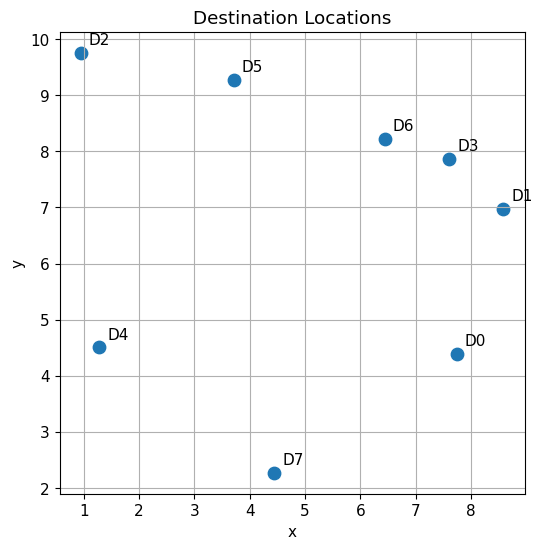

In [4]:
# 3.3 配送先の可視化

fig, ax = plt.subplots()

ax.scatter(df_points["x"], df_points["y"], s=80)

for _, row in df_points.iterrows():
    ax.text(row["x"] + 0.15, row["y"] + 0.15, row["destination"])

ax.set_title("Destination Locations")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True)

plt.show()

### 3.4 配送先どうしの関係を数値で表す

配送先をどのように分けるかを考えるためには、配送先どうしの関係を数値として表しておくと便利です。  
ここでは単純な例として、配送先間の距離を計算し、その値をもとに関係の強さを表す行列を作成します。

距離が近い配送先どうしは関係が強い、距離が遠い配送先どうしは関係が弱い、と考えることで、後の最適化問題へつなげやすくなります。

In [5]:
# 3.4 配送先間の距離行列を作成

point_array = df_points[["x", "y"]].to_numpy()

diff = point_array[:, np.newaxis, :] - point_array[np.newaxis, :, :]
distance_matrix = np.sqrt(np.sum(diff**2, axis=2))

df_distance = pd.DataFrame(
    distance_matrix,
    index=df_points["destination"],
    columns=df_points["destination"]
)

df_distance.round(2)

destination,D0,D1,D2,D3,D4,D5,D6,D7
destination,,,,,,,,
D0,0.00,2.72,8.66,3.47,6.46,6.33,4.05,3.92
D1,2.72,0.00,8.13,1.32,7.71,5.39,2.49,6.27
D2,8.66,8.13,0.00,6.93,5.26,2.81,5.71,8.26
D3,3.47,1.32,6.93,0.00,7.17,4.15,1.23,6.43
D4,6.46,7.71,5.26,7.17,0.00,5.35,6.36,3.86
D5,6.33,5.39,2.81,4.15,5.35,0.00,2.92,7.03
D6,4.05,2.49,5.71,1.23,6.36,2.92,0.00,6.28
D7,3.92,6.27,8.26,6.43,3.86,7.03,6.28,0.00


### 3.5 Distance matrix の確認

前のセルで、配送先どうしの距離を表す行列を作成しました。  
次に、この距離行列をヒートマップとして表示し、どの配送先どうしが近いか、あるいは遠いかを視覚的に確認します。

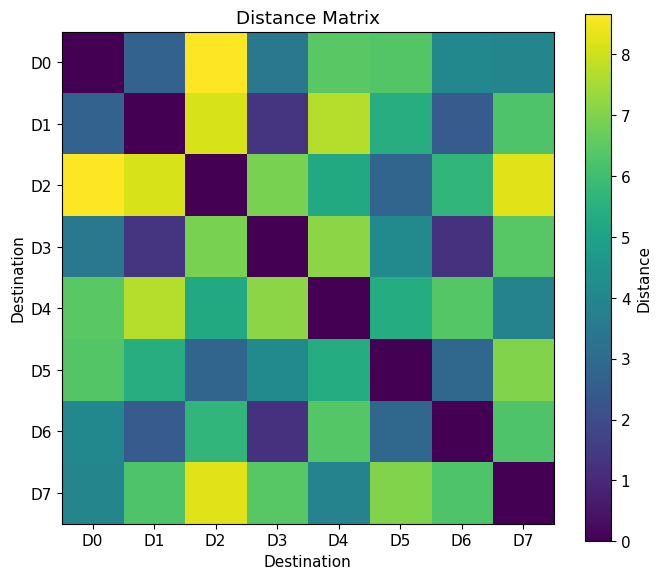

In [6]:
# 3.5 Distance matrix の可視化

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(distance_matrix, cmap="viridis")

ax.set_title("Distance Matrix")
ax.set_xlabel("Destination")
ax.set_ylabel("Destination")
ax.set_xticks(range(n_points))
ax.set_yticks(range(n_points))
ax.set_xticklabels(df_points["destination"])
ax.set_yticklabels(df_points["destination"])

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Distance")

plt.tight_layout()
plt.show()

### 3.6 配送先どうしの関係の強さを作る

距離行列は、配送先どうしの離れ具合を表していました。  
一方で、最適化問題では「近い配送先どうしは関係が強い」といった形で扱いたいことがあります。

そこでここでは、距離が小さいほど大きな値になるように変換し、配送先どうしの関係の強さを表す行列を作成します。

In [7]:
# 3.6 距離から関係の強さを作成

# 0除算を避けるため、対角成分以外にだけ変換を適用
strength_matrix = np.zeros_like(distance_matrix)

for i in range(n_points):
    for j in range(n_points):
        if i != j:
            strength_matrix[i, j] = 1.0 / (1.0 + distance_matrix[i, j])

df_strength = pd.DataFrame(
    strength_matrix,
    index=df_points["destination"],
    columns=df_points["destination"]
)

df_strength.round(3)

destination,D0,D1,D2,D3,D4,D5,D6,D7
destination,,,,,,,,
D0,0.000,0.269,0.104,0.224,0.134,0.136,0.198,0.203
D1,0.269,0.000,0.109,0.431,0.115,0.156,0.287,0.138
D2,0.104,0.109,0.000,0.126,0.160,0.263,0.149,0.108
D3,0.224,0.431,0.126,0.000,0.122,0.194,0.449,0.135
D4,0.134,0.115,0.160,0.122,0.000,0.158,0.136,0.206
D5,0.136,0.156,0.263,0.194,0.158,0.000,0.255,0.124
D6,0.198,0.287,0.149,0.449,0.136,0.255,0.000,0.137
D7,0.203,0.138,0.108,0.135,0.206,0.124,0.137,0.000


### 3.7 Relationship matrix の可視化

作成した関係の強さの行列も、ヒートマップとして表示して確認します。  
値が大きい組み合わせほど、配送先どうしの関係が強いことを表しています。

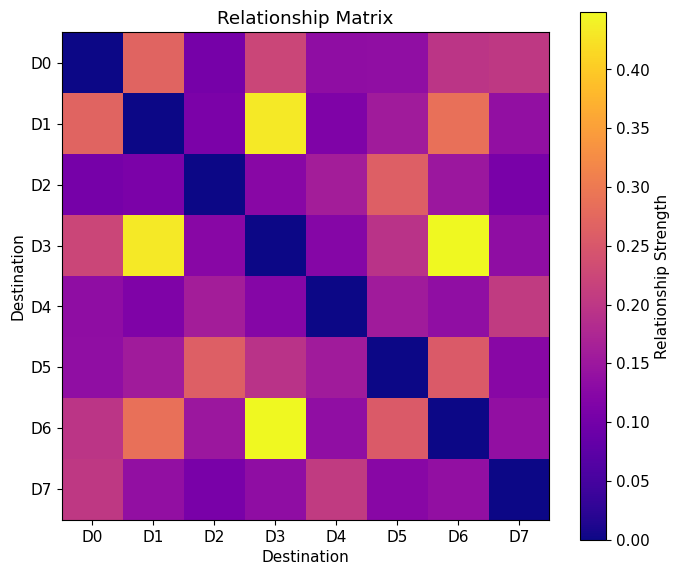

In [8]:
# 3.7 関係の強さ行列の可視化

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(strength_matrix, cmap="plasma")

ax.set_title("Relationship Matrix")
ax.set_xlabel("Destination")
ax.set_ylabel("Destination")
ax.set_xticks(range(n_points))
ax.set_yticks(range(n_points))
ax.set_xticklabels(df_points["destination"])
ax.set_yticklabels(df_points["destination"])

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Relationship Strength")

plt.tight_layout()
plt.show()

### 3.8 ここまでの整理

ここまでで、配送先の位置データを作成し、配送先どうしの距離と関係の強さを行列として表しました。

このように、配送先間の関係を数値で表しておくと、次の段階で「どの配送先をどちらのチームへ割り当てるか」を、コンピュータで探索しやすい最適化問題として表現しやすくなります。

次章では、各配送先の割当を 0/1 で表し、配送先割当問題を最適化問題として整理していきます。

## 4. 配送先割当問題を 0/1 の最適化問題として表す

ここまでで、配送先の位置と、配送先どうしの関係の強さを表す行列を準備しました。  
次は、この情報を使って、配送先を2つの配送チームへ割り当てる問題を、量子コンピュータで扱える形に整理します。

本チュートリアルでは、各配送先について「Team A に割り当てるか」「Team B に割り当てるか」を 0/1 の値で表します。  
このように表現することで、配送先全体の割当パターンを、0 と 1 の組合せとして扱えるようになります。

この章では、まず 0/1 による表し方を確認し、その後で問題全体を QUBO として表現します。

### 4.1 配送先の割当を 0/1 で表す

まずは、各配送先をどちらのチームに割り当てるかを、単純な 0/1 の値で表します。  
ここでは、次のような約束で考えます。

- 0: Team A に割り当てる
- 1: Team B に割り当てる

たとえば配送先が 4 つある場合、`[0, 1, 0, 1]` という並びは、1番目と3番目を Team A、2番目と4番目を Team B に割り当てることを表します。

このようにすると、配送先の割当全体を 1 本の 0/1 ベクトルとして扱うことができます。

In [9]:
# 4.1 0/1 による割当の例

example_assignment = np.array([0, 1, 0, 1])

df_example = pd.DataFrame({
    "destination": [f"D{i}" for i in range(len(example_assignment))],
    "assignment": example_assignment,
    "team": ["Team A" if x == 0 else "Team B" for x in example_assignment]
})

df_example

,destination,assignment,team
0,D0,0,Team A
1,D1,1,Team B
2,D2,0,Team A
3,D3,1,Team B


### 4.2 割当の良し悪しをスコアとして考える

配送先を 0/1 で表せるようになると、次に考えたいのは「どの割当が良いか」です。

ここでは単純な例として、**関係の強い配送先どうしが別のチームに分かれるほど、高いスコアになる** と考えます。  
つまり、配送先どうしの関係の強さをもとに、各割当パターンに点数をつけ、その点数が高い割当を探すという流れです。

このように「0/1 の組合せに対してスコアを与え、その良い組合せを探す」形にすると、最適化問題として扱いやすくなります。

In [10]:
# 4.2 割当に対するスコアを計算する関数

def evaluate_assignment(assignment, strength_matrix):
    """
    関係の強い配送先どうしが別チームに分かれるほど
    スコアが高くなるように評価する。
    """
    n = len(assignment)
    score = 0.0

    for i in range(n):
        for j in range(i + 1, n):
            if assignment[i] != assignment[j]:
                score += strength_matrix[i, j]

    return score

In [11]:
# 4.2 いくつかの割当例でスコアを確認

assignment_a = np.array([0, 0, 0, 0, 1, 1, 1, 1])
assignment_b = np.array([0, 1, 0, 1, 0, 1, 0, 1])
assignment_c = np.array([0, 0, 1, 1, 0, 1, 0, 1])

scores = pd.DataFrame({
    "assignment": [
        assignment_a.tolist(),
        assignment_b.tolist(),
        assignment_c.tolist(),
    ],
    "score": [
        evaluate_assignment(assignment_a, strength_matrix),
        evaluate_assignment(assignment_b, strength_matrix),
        evaluate_assignment(assignment_c, strength_matrix),
    ]
})

scores

,assignment,score
0,"[0, 0, 0, 0, 1, 1, 1, 1]",2.946337
1,"[0, 1, 0, 1, 0, 1, 0, 1]",3.166098
2,"[0, 0, 1, 1, 0, 1, 0, 1]",3.136826


### 4.3 QUBO として表す考え方

このチュートリアルでは、配送先割当問題を **QUBO** と呼ばれる形で表します。  
QUBO は、0/1 の変数からなる組合せ問題を、行列を使って扱いやすくする表現方法です。

ここでは数式による説明は行わず、次のように理解すれば十分です。

- 各配送先の割当を 0/1 で表す
- 割当の良し悪しを、行列を使って計算できるようにする
- その行列をソルバーへ渡して、よい割当を探索する

つまり、QUBO は「配送先割当問題を、ソルバーで解きやすいデータ構造へ整理したもの」と考えることができます。

### 4.4 QUBO 行列を作成する

次に、配送先どうしの関係の強さをもとに、QUBO 行列を作成します。  
ここでは、関係の強い配送先どうしが別のチームへ分かれるような割当を好むように、簡単な形で行列を構成します。

この行列は、この後 `qudas` に渡して最適化を行うための基本データになります。

In [12]:
# 4.4 QUBO 行列を作成する関数

def build_qubo_from_strength(strength_matrix):
    """
    関係の強い配送先どうしが別チームに分かれると
    エネルギーが小さくなるような QUBO 行列を作成する。
    """
    n = strength_matrix.shape[0]
    qubo = np.zeros((n, n), dtype=float)

    for i in range(n):
        for j in range(i + 1, n):
            w = strength_matrix[i, j]

            # x_i != x_j のときにエネルギーが下がる形
            qubo[i, i] += -w
            qubo[j, j] += -w
            qubo[i, j] += 2 * w

    return qubo

In [13]:
# 4.4 QUBO 行列の作成

qubo_matrix = build_qubo_from_strength(strength_matrix)

df_qubo = pd.DataFrame(
    qubo_matrix,
    index=df_points["destination"],
    columns=df_points["destination"]
)

df_qubo.round(3)

destination,D0,D1,D2,D3,D4,D5,D6,D7
destination,,,,,,,,
D0,-1.267,0.538,0.207,0.447,0.268,0.273,0.396,0.406
D1,0.000,-1.505,0.219,0.863,0.230,0.313,0.574,0.275
D2,0.000,0.000,-1.018,0.252,0.319,0.525,0.298,0.216
D3,0.000,0.000,0.000,-1.681,0.245,0.388,0.897,0.269
D4,0.000,0.000,0.000,0.000,-1.030,0.315,0.272,0.411
D5,0.000,0.000,0.000,0.000,0.000,-1.287,0.510,0.249
D6,0.000,0.000,0.000,0.000,0.000,0.000,-1.611,0.275
D7,0.000,0.000,0.000,0.000,0.000,0.000,0.000,-1.051


### 4.5 QUBO 行列の確認

作成した QUBO 行列を、そのまま表として見るだけでは全体の傾向をつかみにくいことがあります。  
そこで次のセルでは、QUBO 行列をヒートマップとして表示し、値の分布を視覚的に確認します。

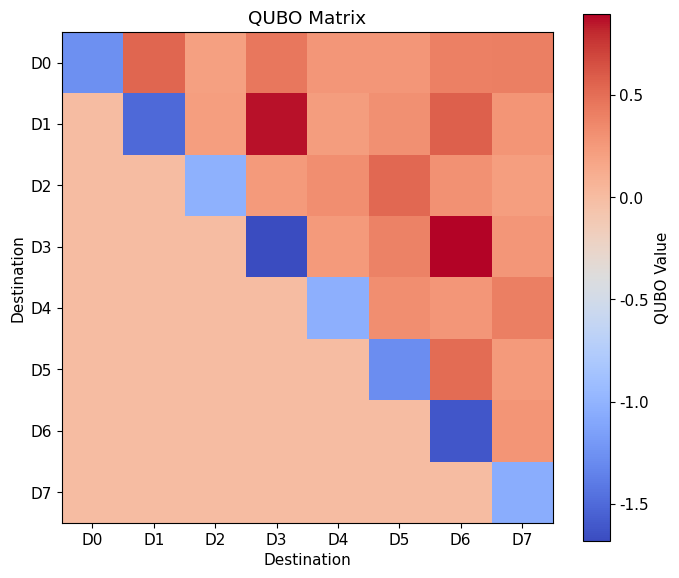

In [14]:
# 4.5 QUBO 行列の可視化

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(qubo_matrix, cmap="coolwarm")

ax.set_title("QUBO Matrix")
ax.set_xlabel("Destination")
ax.set_ylabel("Destination")
ax.set_xticks(range(n_points))
ax.set_yticks(range(n_points))
ax.set_xticklabels(df_points["destination"])
ax.set_yticklabels(df_points["destination"])

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("QUBO Value")

plt.tight_layout()
plt.show()

### 4.6 ここまでの整理

ここまでで、配送先割当問題を 0/1 の組合せとして表し、その良し悪しを行列ベースで評価できる形へ整理しました。  
このようにして得られた QUBO 行列は、組合せ最適化ソルバーへ入力しやすい形式になっています。

次章では、この QUBO 行列を `qudas` で扱える形へ変換し、実際に配送先割当を解いていきます。

## 5. `qudas` を用いて配送先割当問題を解く

前章では、配送先割当問題を QUBO 行列として表現しました。  
この章では、その QUBO 行列を `qudas` で扱える形に変換し、実際にソルバーを使って解を求めます。

ここでは、別の Python プログラムを呼び出すのではなく、この Notebook の中でそのまま処理を進めます。  
そのため、QUBO の作成から求解、結果の解釈までを 1 つの流れとして確認できます。

### 5.1 `qudas` とソルバー関連ライブラリの読み込み

まずは、QUBO 行列を `qudas` で扱うために必要なライブラリを読み込みます。  
あわせて、今回使用するソルバーも読み込みます。

In [15]:
# 5.1 qudas とソルバー関連ライブラリの読み込み

from qudas import QuData
from neal import SimulatedAnnealingSampler

print("qudas and solver libraries loaded successfully.")

qudas and solver libraries loaded successfully.


### 5.2 QUBO 行列を `QuData` に変換する

`qudas` では、QUBO 行列をそのまま扱うのではなく、共通データ形式である `QuData` に変換して利用します。  
これにより、同じ問題を複数のソルバーへ渡しやすくなります。

In [16]:
# 5.2 QUBO 行列を QuData に変換

qudata = QuData.input().from_array(qubo_matrix)

print("QUBO matrix has been converted to QuData.")
print(type(qudata))

QUBO matrix has been converted to QuData.
<class 'qudas.annealing.ir.QdAnnealingIR'>


### 5.3 `neal` で解くための関数を用意する

ここでは、まずシミュレーテッドアニーリングを用いる `neal` を使って問題を解きます。  
`qudas` から `dimod` 形式へ変換し、その後ソルバーへ渡す流れを関数としてまとめておきます。

In [17]:
# 5.3 neal で解く関数

def solve_with_neal(qudata, num_reads=100):
    """
    QuData を dimod Binary Quadratic Model に変換し、
    neal で最適化を実行する。
    """
    bqm = qudata.to_dimod_bqm()

    sampler = SimulatedAnnealingSampler()
    sampleset = sampler.sample(bqm, num_reads=num_reads)

    best = sampleset.first

    result = {
        "solver": "neal",
        "assignment": dict(best.sample),
        "energy": float(best.energy),
    }
    return result

### 5.4 解の形式を確認する

ソルバーが返す結果には、各変数の 0/1 値とエネルギー値が含まれます。  
ここでは、後で可視化しやすいように、変数の並びを NumPy 配列へ戻す補助関数も用意しておきます。

In [18]:
# 5.4 解を NumPy 配列へ変換する関数

import re

def assignment_dict_to_array(assignment_dict):
    """
    ソルバー結果の dict 形式を、
    変数番号順の NumPy 配列へ変換する。

    想定するキー例:
    - 0
    - "0"
    - "q_0"
    - その他、末尾に番号を含む文字列
    """
    def extract_index(key):
        key_str = str(key)

        # 末尾の整数を取得
        match = re.search(r"(\d+)$", key_str)
        if match is None:
            raise ValueError(f"Cannot extract variable index from key: {key_str}")

        return int(match.group(1))

    sorted_items = sorted(assignment_dict.items(), key=lambda x: extract_index(x[0]))
    return np.array([int(v) for _, v in sorted_items], dtype=int)

### 5.5 実際に問題を解いてみる

準備ができたので、`neal` を用いて配送先割当問題を解きます。  
得られた解は、この後のセルで配送チーム割当として見やすい形へ戻して確認します。

In [19]:
# 5.5 neal で問題を解く

result_neal = solve_with_neal(qudata, num_reads=200)

result_neal

{'solver': 'neal',
 'assignment': {'q_0': np.int8(0),
  'q_1': np.int8(1),
  'q_2': np.int8(1),
  'q_3': np.int8(0),
  'q_4': np.int8(0),
  'q_5': np.int8(0),
  'q_6': np.int8(1),
  'q_7': np.int8(1)},
 'energy': -3.328470004632223}

### 5.6 解ベクトルを確認する

ソルバーが返した解を、配送先ごとの 0/1 割当に戻して確認します。  
ここでの 0/1 は、次のようにチーム割当に対応しています。

- 0: Team A
- 1: Team B

In [20]:
# 5.6 解ベクトルを NumPy 配列へ変換

best_assignment = assignment_dict_to_array(result_neal["assignment"])

best_assignment

array([0, 1, 1, 0, 0, 0, 1, 1])

### 5.7 配送先ごとのチーム割当として表示する

最後に、求めた 0/1 の解を、配送先ごとの Team A / Team B の割当として表形式で表示します。  
これにより、どの配送先がどちらのチームに割り当てられたかを確認しやすくなります。

In [21]:
# 5.7 配送先ごとのチーム割当として整理

df_solution = df_points.copy()
df_solution["assignment"] = best_assignment
df_solution["team"] = df_solution["assignment"].map({0: "Team A", 1: "Team B"})

df_solution[["destination", "x", "y", "assignment", "team"]]

,destination,x,y,assignment,team
0,D0,7.739560,4.388784,0,Team A
1,D1,8.585979,6.973680,1,Team B
2,D2,0.941773,9.756224,1,Team B
3,D3,7.611397,7.860643,0,Team A
4,D4,1.281136,4.503859,0,Team A
5,D5,3.707980,9.267650,0,Team A
6,D6,6.438651,8.227616,1,Team B
7,D7,4.434142,2.272387,1,Team B


## 6. 求めた配送先割当結果を確認する

前章では、`qudas` を用いて配送先割当問題を解き、各配送先を 0/1 で表した割当結果を得ました。  
この章では、その解を配送チーム割当として見やすく可視化し、どのような分割になったのかを確認します。

また、得られた割当がどの程度よいものかを、これまでに用意した評価関数を使って確認します。

### 6.1 配送先のチーム割当を散布図で表示する

まずは、求めた解を使って、各配送先が Team A と Team B のどちらに割り当てられたかを散布図で表示します。  
色分けして表示することで、割当結果の全体像を直感的に確認できます。

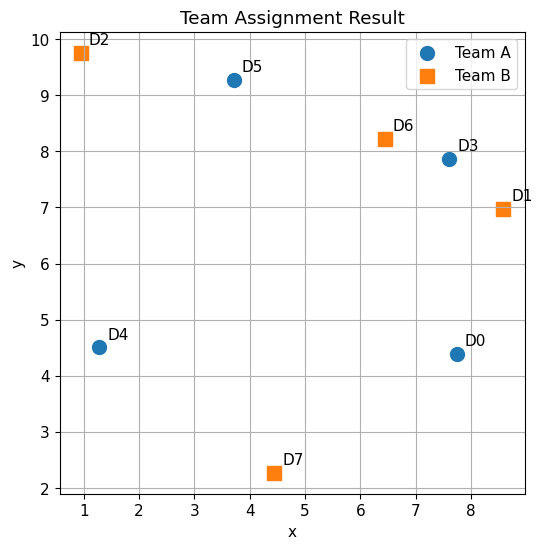

In [22]:
# 6.1 配送先のチーム割当を可視化

fig, ax = plt.subplots()

for team_name, marker in [("Team A", "o"), ("Team B", "s")]:
    subset = df_solution[df_solution["team"] == team_name]
    ax.scatter(
        subset["x"],
        subset["y"],
        s=100,
        marker=marker,
        label=team_name
    )

for _, row in df_solution.iterrows():
    ax.text(row["x"] + 0.15, row["y"] + 0.15, row["destination"])

ax.set_title("Team Assignment Result")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True)
ax.legend()

plt.show()

### 6.2 割当結果のスコアを確認する

次に、得られた割当結果に対して、前章で定義した評価関数を適用します。  
ここでは、関係の強い配送先どうしが別チームに分かれるほど高い値になるようにスコアを計算します。

このスコアは、**大きいほど望ましい割当**を表します。  
一方で、ソルバーが内部で扱っている energy は最小化の対象であるため、**小さいほど望ましい値**になります。

したがって、このチュートリアルでは、結果を見るときに

- score は大きいほど良い
- energy は小さいほど良い

という対応で確認します。

In [23]:
# 6.2 得られた割当のスコアを計算

best_score = evaluate_assignment(best_assignment, strength_matrix)

print("Best assignment:")
print(best_assignment)
print(f"Score: {best_score:.4f}")
print(f"Energy: {result_neal['energy']:.4f}")

Best assignment:
[0 1 1 0 0 0 1 1]
Score: 3.3285
Energy: -3.3285


### 6.3 割当結果を表として確認する

散布図だけでなく、各配送先の座標と割当先を表として確認しておくと、後で比較しやすくなります。  
ここでは、配送先名、座標、0/1 の割当、チーム名を一覧で表示します。

In [24]:
# 6.3 割当結果の表を整える

df_solution_summary = df_solution[["destination", "x", "y", "assignment", "team"]].copy()
df_solution_summary = df_solution_summary.sort_values("destination").reset_index(drop=True)

df_solution_summary

,destination,x,y,assignment,team
0,D0,7.739560,4.388784,0,Team A
1,D1,8.585979,6.973680,1,Team B
2,D2,0.941773,9.756224,1,Team B
3,D3,7.611397,7.860643,0,Team A
4,D4,1.281136,4.503859,0,Team A
5,D5,3.707980,9.267650,0,Team A
6,D6,6.438651,8.227616,1,Team B
7,D7,4.434142,2.272387,1,Team B


### 6.4 ランダムな割当と比較する

得られた解の良し悪しをよりわかりやすくするために、ランダムに作った割当とスコアを比較してみます。  
これにより、ソルバーによって得られた解が、単なる適当な分割よりもよい値を持っているかを確認できます。

In [25]:
# 6.4 ランダム割当との比較

random_assignment = rng.integers(0, 2, size=n_points)
random_score = evaluate_assignment(random_assignment, strength_matrix)

comparison_df = pd.DataFrame({
    "type": ["solver result", "random assignment"],
    "assignment": [best_assignment.tolist(), random_assignment.tolist()],
    "score": [best_score, random_score]
})

comparison_df

,type,assignment,score
0,solver result,"[0, 1, 1, 0, 0, 0, 1, 1]",3.328470
1,random assignment,"[0, 1, 1, 0, 1, 1, 0, 1]",2.818716


### 6.5 ここまでの整理

ここまでで、`qudas` を用いて求めた配送先割当結果を可視化し、そのスコアを確認しました。  
これにより、配送先割当問題を 0/1 最適化問題として表し、実際に解いて解釈するまでの流れを一通り確認できました。

次章からは発展編として、同じ問題を量子回路として扱う考え方に進みます。  
まずは、配送先割当問題を量子ビットと対応づけて考える流れを確認します。

## 7. 配送先割当問題を量子回路として考える

ここまでで、配送先割当問題を 0/1 の最適化問題として表し、`qudas` を使って解く流れを確認しました。  
次は発展編として、同じ問題を量子回路として扱う考え方を見ていきます。

ここでの目的は、量子アルゴリズムの理論を厳密に学ぶことではありません。  
むしろ、配送先ごとの 0/1 の割当を量子ビットの状態と対応づけることで、同じ問題を別の見方で表せることを理解することにあります。

また、後の章で `QuantumCircuitCutting` による回路分割を試すために、まずは小規模な問題を対象として量子回路を作る準備を行います。

### 7.1 配送先の割当と量子ビットの対応

これまで、各配送先の割当を 0/1 で表してきました。  
量子回路として考える場合も、この 0/1 の情報を量子ビットの状態と対応づけることで、同じ問題を別の表現で扱うことができます。

たとえば、1つの配送先に対して1つの量子ビットを対応させると、

- 0: Team A
- 1: Team B

という対応をそのまま使うことができます。

このようにすると、配送先が 4 個であれば 4 量子ビット、配送先が 6 個であれば 6 量子ビットという形で、問題サイズに応じた量子回路を考えることができます。

### 7.2 後半では小規模な問題を扱う

前半では、配送先数 8 の例を用いて最適化問題を解きました。  
一方で、量子回路を扱う後半では、回路の構造や分割の流れを見やすくするために、より小規模な例を用います。

ここでは、配送先数を 4 から 6 程度にした問題を対象として、量子回路を作成し、`QuantumCircuitCutting` による回路分割を確認します。

これは、実務で扱う問題をそのまま量子回路に載せることが目的ではなく、まずは回路化と分割の考え方を理解しやすくするためです。

In [26]:
# 7.2 小規模問題用の配送先データを作成

n_small = 4

coords_small = rng.uniform(low=0, high=10, size=(n_small, 2))

df_points_small = pd.DataFrame(coords_small, columns=["x", "y"])
df_points_small["destination"] = [f"S{i}" for i in range(n_small)]

df_points_small

,x,y,destination
0,7.580877,3.545260,S0
1,9.706980,8.931211,S1
2,7.783835,1.946387,S2
3,4.667210,0.438038,S3


### 7.3 小規模問題の配送先を可視化する

後半で扱う小規模問題についても、まずは配送先の位置関係を確認しておきます。  
前半と同様に、平面上の点として表示することで、どの配送先が近い位置にあるかを見やすくします。

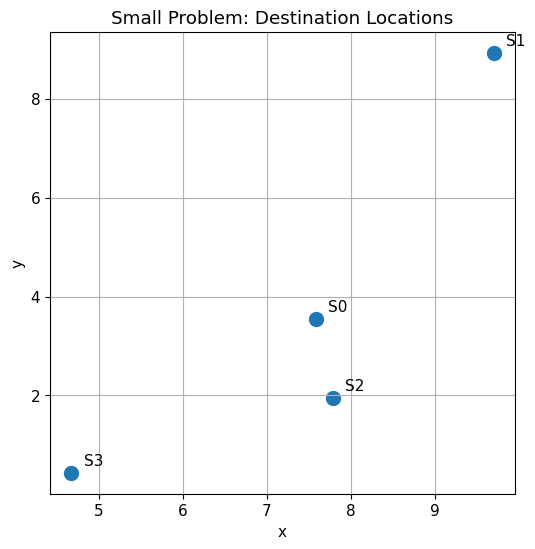

In [27]:
# 7.3 小規模問題の配送先を可視化

fig, ax = plt.subplots()

ax.scatter(df_points_small["x"], df_points_small["y"], s=100)

for _, row in df_points_small.iterrows():
    ax.text(row["x"] + 0.15, row["y"] + 0.15, row["destination"])

ax.set_title("Small Problem: Destination Locations")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True)

plt.show()

### 7.4 小規模問題の関係行列を作成する

前半と同じ考え方で、小規模問題についても配送先間の距離と関係の強さを計算します。  
これにより、後で量子回路に対応づける対象となる問題データを準備できます。

In [28]:
# 7.4 小規模問題の距離行列と関係行列を作成

point_array_small = df_points_small[["x", "y"]].to_numpy()

diff_small = point_array_small[:, np.newaxis, :] - point_array_small[np.newaxis, :, :]
distance_matrix_small = np.sqrt(np.sum(diff_small**2, axis=2))

strength_matrix_small = np.zeros_like(distance_matrix_small)

for i in range(n_small):
    for j in range(n_small):
        if i != j:
            strength_matrix_small[i, j] = 1.0 / (1.0 + distance_matrix_small[i, j])

df_strength_small = pd.DataFrame(
    strength_matrix_small,
    index=df_points_small["destination"],
    columns=df_points_small["destination"]
)

df_strength_small.round(3)

destination,S0,S1,S2,S3
destination,,,,
S0,0.000,0.147,0.383,0.190
S1,0.147,0.000,0.121,0.092
S2,0.383,0.121,0.000,0.224
S3,0.190,0.092,0.224,0.000


### 7.5 小規模問題の QUBO を作成する

量子回路として扱う前に、小規模問題についても前半と同様に QUBO 行列を作成しておきます。  
これにより、前半の配送先割当問題と後半の量子回路パートが、同じ問題設定の上にあることがわかりやすくなります。

In [29]:
# 7.5 小規模問題の QUBO 行列を作成

qubo_matrix_small = build_qubo_from_strength(strength_matrix_small)

df_qubo_small = pd.DataFrame(
    qubo_matrix_small,
    index=df_points_small["destination"],
    columns=df_points_small["destination"]
)

df_qubo_small.round(3)

destination,S0,S1,S2,S3
destination,,,,
S0,-0.72,0.295,0.766,0.380
S1,0.00,-0.361,0.243,0.184
S2,0.00,0.000,-0.728,0.448
S3,0.00,0.000,0.000,-0.506


### 7.6 ここまでの整理

ここまでで、後半で使用する小規模な配送先割当問題を準備しました。  
前半と同じ考え方で配送先間の関係を数値化し、それを QUBO 行列として表現できていることを確認しました。

次章では、この小規模問題をもとに、実際に量子回路を作成していきます。

## 8. QuantumCircuitCutting を用いた回路分割の流れ

ここからは、前章で用意した小規模な配送先割当問題を対象として、QuantumCircuitCutting を用いた回路分割の流れを確認します。

本チュートリアルで扱う QuantumCircuitCutting は、`quantum_circuit_cutting` を含む関連ライブラリ群を利用して、量子回路の変換、カット位置の特定、回路分割、実行準備を行うためのものです。

前半では、物流問題を 0/1 の最適化問題として解きました。後半では、その問題に対応する量子回路を用意し、QuantumCircuitCutting を使ってより小さな部分回路へ分割する流れを確認します。

### 8.1 この章で行うこと

この章では、次の流れで進めます。

1. 小規模な配送先割当問題に対応する量子回路を用意する
2. QuantumCircuitCutting 系ライブラリで扱いやすい形へ変換する
3. カット候補や分割位置を確認する
4. 回路を複数の部分回路へ分割する
5. 分割後の回路を確認する

この章では、まず「分割の流れを理解する」ことを重視し、理論の詳細よりも処理のつながりを追いやすくする構成にします。

### 8.2 小規模問題に対応する量子回路を準備する

前章で作成した小規模な QUBO 行列をもとに、回路分割の対象となる量子回路を準備します。

ここでは、厳密な量子アルゴリズムの最適実装を目指すのではなく、配送先割当問題に対応した相互作用を含む回路を用意し、QuantumCircuitCutting に入力する対象を作ることを目的とします。

In [30]:
# 8.2 小規模問題に対応する量子回路を準備する

from qiskit import QuantumCircuit

def build_problem_circuit_from_qubo(qubo_matrix, gamma=0.6, beta=0.4):
    """
    小規模な QUBO 行列から、回路分割の対象となる量子回路を作成する。
    ここではワイヤカットしやすくするため、隣接量子ビット間の相互作用だけを使う。
    """
    n = qubo_matrix.shape[0]
    qc = QuantumCircuit(n)

    # 初期状態
    for i in range(n):
        qc.h(i)

    # 対角項
    for i in range(n):
        if abs(qubo_matrix[i, i]) > 1e-12:
            qc.rz(2.0 * gamma * qubo_matrix[i, i], i)

    # 隣接量子ビット間だけ相互作用を入れる
    for i in range(n - 1):
        j = i + 1
        if abs(qubo_matrix[i, j]) > 1e-12:
            qc.cx(i, j)
            qc.rz(2.0 * gamma * qubo_matrix[i, j], j)
            qc.cx(i, j)

    # ミキサー
    for i in range(n):
        qc.rx(2.0 * beta, i)

    return qc

qc_small = build_problem_circuit_from_qubo(
    qubo_matrix_small,
    gamma=0.6,
    beta=0.4
)

qc_small

### 8.3 回路図を確認する

作成した回路を表示し、どの量子ビット間に相互作用が入っているかを確認します。

後で回路分割を行うときには、このような 2 量子ビットゲートの配置が、どこを切るかを考える手がかりになります。

In [31]:
# 8.3 回路図を確認する

qc_small.draw("text")

┌───┐┌──────────────┐                         ┌─────────┐               »
q_0: ┤ H ├┤ Rz(-0.86434) ├──■───────────────────■──┤ Rx(0.8) ├───────────────»
     ├───┤├─────────────┬┘┌─┴─┐┌─────────────┐┌─┴─┐└─────────┘               »
q_1: ┤ H ├┤ Rz(-0.4326) ├─┤ X ├┤ Rz(0.35344) ├┤ X ├─────■────────────────────»
     ├───┤├─────────────┴┐└───┘└─────────────┘└───┘   ┌─┴─┐   ┌─────────────┐»
q_2: ┤ H ├┤ Rz(-0.87393) ├────────────────────────────┤ X ├───┤ Rz(0.29109) ├»
     ├───┤├─────────────┬┘                            └───┘   └─────────────┘»
q_3: ┤ H ├┤ Rz(-0.6074) ├────────────────────────────────────────────────────»
     └───┘└─────────────┘                                                    »
«                                                    
«q_0: ───────────────────────────────────────────────
«          ┌─────────┐                               
«q_1: ──■──┤ Rx(0.8) ├───────────────────────────────
«     ┌─┴─┐└─────────┘                    ┌─────────┐
«q_2: ┤ X ├─────■──────────────────────■──┤ Rx(0.8) ├
«     └───┘   ┌─┴─┐   ┌─────────────┐┌─┴─┐├─────────┤
«q_3: ────────┤ X ├───┤ Rz(0.53782) ├┤ X ├┤ Rx(0.8) ├
«             └───┘   └─────────────┘└───┘└─────────┘

## 9. QuantumCircuitCutting で回路分割を行う

QuantumCircuitCutting を用いて、回路分割の処理を行います。

このライブラリ群は、単一の回路分割関数だけではなく、回路変換、カット位置探索、回路分割、再構成準備といった複数の役割を持つモジュール群から構成されています。

そのため、この章では細かな内部理論よりも、

- 入力回路を準備する
- 分割しやすい形へ変換する
- カット位置を決める
- 回路を分割する

という処理の流れが見えるように進めます。

### 9.1 QuantumCircuitCutting 系ライブラリを読み込む

まずは、QuantumCircuitCutting の統合パッケージと、今回のチュートリアルで使用する主要モジュールを読み込みます。

この環境では、回路分割に関連する主なモジュールとして、次のものが利用できます。

- `quantum_circuit_cutting`
- `circuit_cut_point_locator`
- `circuit_cutter`

このうち、`circuit_cut_point_locator` はカット位置の探索、`circuit_cutter` は部分回路の生成に対応するモジュールです。  
以後のセルでは、これらを使って QuantumCircuitCutting の流れを確認していきます。

In [32]:
# 9.1 QuantumCircuitCutting 系ライブラリを読み込む

import quantum_circuit_cutting as qcc
import circuit_cut_point_locator
import circuit_cutter

print("QuantumCircuitCutting libraries loaded successfully.")
print("qcc                    :", qcc.__name__)
print("cut point locator      :", circuit_cut_point_locator.__name__)
print("circuit cutter         :", circuit_cutter.__name__)

QuantumCircuitCutting libraries loaded successfully.
qcc                    : quantum_circuit_cutting
cut point locator      : circuit_cut_point_locator
circuit cutter         : circuit_cutter


### 9.2 カット位置を自動探索する

次に、QuantumCircuitCutting のカット位置探索機能を使って、どのゲートを分割候補とするかを調べます。

カット位置探索では、回路をどのような量子ビット接続上で実行するかという情報が必要になります。  
ここでは簡単な例として、4量子ビットが一直線につながった構成

`0 - 1 - 2 - 3`

を想定し、その接続情報を `coupling_map` として与えます。

この設定のもとで、1か所だけカットする候補を自動探索します。

In [33]:
# 9.2 カット位置を自動探索する

# 4量子ビットの直線接続を仮定
coupling_map = [
    [0, 1], [1, 0],
    [1, 2], [2, 1],
    [2, 3], [3, 2],
]

num_cut = 1

best_cut_gate_ids = circuit_cut_point_locator.locate_best_cut_gate_id_lst(
    qc_small,
    num_cut=num_cut,
    coupling_map=coupling_map,
    verbose=True
)

print("Best cut gate ids:")
print(best_cut_gate_ids)

2026-04-22 05:10:38,276	INFO worker.py:2012 -- Started a local Ray instance.
/mnt/c/Users/E1804/work/development/circuit-transformer/circuit-transformer-main/.venv-ubuntu/lib/python3.12/site-packages/ray/_private/worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(


0th circuit
['cx', 'cnot', 'cz'] count: 5
depth: 9
1th circuit
['cx', 'cnot', 'cz'] count: 5
depth: 10
2th circuit
['cx', 'cnot', 'cz'] count: 5
depth: 10
3th circuit
['cx', 'cnot', 'cz'] count: 5
depth: 10
4th circuit
['cx', 'cnot', 'cz'] count: 5
depth: 10
5th circuit
['cx', 'cnot', 'cz'] count: 5
depth: 9
Min ['cx', 'cnot', 'cz'] count: 5, min depth 9 at {min_id}th circuit
Best cut gate ids:
((8,), 5, 9, <qiskit.circuit.quantumcircuit.QuantumCircuit object at 0x793ae0983a40>)


### 9.3 カット候補のゲート番号を整理する

自動探索の結果には、カット候補のゲート番号以外の情報が含まれる場合があります。  
そこでここでは、回路中のゲート番号として使える整数だけを取り出し、分割候補として整理します。

このようにしておくことで、後のセルで「どのゲートを分割対象とするか」を扱いやすくなります。

In [34]:
# 9.3 カット候補のゲート番号を整理する

def collect_gate_ids_from_locator_output(locator_output):
    gate_ids = []

    for item in locator_output:
        if isinstance(item, int):
            gate_ids.append(item)
        elif isinstance(item, tuple):
            gate_ids.extend([x for x in item if isinstance(x, int)])

    # 重複を除き、昇順にそろえる
    gate_ids = sorted(set(gate_ids))
    return gate_ids

cut_gate_ids = collect_gate_ids_from_locator_output(best_cut_gate_ids)

print("Cut gate ids:")
print(cut_gate_ids)

Cut gate ids:
[5, 8, 9]


### 9.4 カット候補に対応するゲートを確認する

整理したゲート番号が、回路中のどのゲートに対応しているかを確認します。

ここでは、ゲート番号、ゲート名、作用する量子ビットを表として表示します。  
これにより、QuantumCircuitCutting がどの相互作用を分割候補として選んだのかを、回路の内容と結びつけて理解しやすくなります。

In [35]:
# 9.4 カット候補に対応するゲートを表で確認する

cut_gate_rows = []

for gate_id in cut_gate_ids:
    instr = qc_small.data[gate_id]
    operation = instr.operation
    qubits = instr.qubits

    qubit_indices = [qc_small.find_bit(q).index for q in qubits]

    cut_gate_rows.append({
        "gate_id": gate_id,
        "operation": operation.name,
        "qubits": qubit_indices,
        "params": [float(p) if hasattr(p, "__float__") else str(p) for p in operation.params],
    })

df_cut_gates = pd.DataFrame(cut_gate_rows)
df_cut_gates

,gate_id,operation,qubits,params
0,5,rz,[1],[-0.4326030547347596]
1,8,cx,"[0, 1]",[]
2,9,rz,[1],[0.3534399034074141]


### 9.5 分割対象とする 2 量子ビットゲートを選ぶ

カット候補の中には、1量子ビットゲートが含まれる場合があります。  
しかし、回路分割では一般に 2 量子ビットゲートが主要な分割対象になります。

そこでここでは、カット候補の中から 2 量子ビットゲートだけを抽出し、この後の分割対象として用います。

In [36]:
# 9.5 分割対象とする 2 量子ビットゲートを選ぶ

df_two_qubit_cut_gates = df_cut_gates[df_cut_gates["qubits"].apply(lambda x: len(x) == 2)].reset_index(drop=True)

df_two_qubit_cut_gates

,gate_id,operation,qubits,params
0,8,cx,"[0, 1]",[]


### 9.6 分割対象とするゲートを選ぶ

ここでは、抽出した 2 量子ビットゲートのうち、最初の 1 つを分割対象として選びます。

実際の応用では、どのゲートを切るかによって、分割後の回路の大きさや再構成コストが変わります。  
本チュートリアルでは、まず流れを理解しやすくするために、単純に 1 つのゲートを選んで進めます。

In [37]:
# 9.6 分割対象とするゲートを選ぶ

selected_cut_gate_id = int(df_two_qubit_cut_gates.loc[0, "gate_id"])
selected_cut_gate_row = df_two_qubit_cut_gates.loc[0]

print("Selected cut gate:")
print(selected_cut_gate_row)
print(f"\nselected_cut_gate_id = {selected_cut_gate_id}")

Selected cut gate:
gate_id           8
operation        cx
qubits       [0, 1]
params           []
Name: 0, dtype: object

selected_cut_gate_id = 8


### 9.7 分割対象のゲートを確認する

ここでは、選択したゲートを改めて確認し、この後の回路分割で使用する対象を明確にします。

このチュートリアルでは、まず 1 つの 2 量子ビットゲートを分割対象として選び、そのゲートを基準に部分回路へ分ける流れを確認します。

In [38]:
# 9.7 分割対象のゲートを確認する

selected_instr = qc_small.data[selected_cut_gate_id]
selected_operation = selected_instr.operation
selected_qubits = [qc_small.find_bit(q).index for q in selected_instr.qubits]

print("Selected gate for cutting")
print("-------------------------")
print(f"gate_id   : {selected_cut_gate_id}")
print(f"operation : {selected_operation.name}")
print(f"qubits    : {selected_qubits}")
print(f"params    : {selected_operation.params}")

Selected gate for cutting
-------------------------
gate_id   : 8
operation : cx
qubits    : [0, 1]
params    : []


### 9.8 QuantumCircuitCutting 用の設定ファイルを用意する

`MyQuantumCircuit` では、量子ビット名、測定レジスタ名、ゲート名などを解釈するための設定を YAML ファイルから読み込みます。  
そのため、回路を `MyQuantumCircuit` 形式へ変換する前に、まず設定ファイルを用意します。

ここでは、今回のチュートリアルで使用する基本的な設定を YAML ファイルとして保存します。

In [97]:
# 9.8 QuantumCircuitCutting 用の設定ファイルを用意する

from pathlib import Path
import yaml

yaml_path = Path("./qcc_config.yaml")

qcc_config = {
    "openqasm_version": "OPENQASM 3;",
    "HEADER_RE": r"OPENQASM\s+3(?:\.\d+)?\s*;",
    "INCLUDE_RE": r'include\s+"[^"]+"\s*;',

    # qubit 宣言
    # 例: qubit q[4];
    "m_reg_pattern": r"(qubit)\s+([A-Za-z_][A-Za-z0-9_]*)\[(\d+)\]\s*;",
    # 例: qubit[4] q;
    "m_array_pattern": r"qubit\[(\d+)\]\s+([A-Za-z_][A-Za-z0-9_]*)\s*;",
    # 例: qubit q;
    "m_single_pattern": r"(qubit)\s+([A-Za-z_][A-Za-z0-9_]*)\s*;",

    # 互換用
    "QUBIT_DECL_RE": r"(qubit)\s+([A-Za-z_][A-Za-z0-9_]*)\[(\d+)\]\s*;",
    "BIT_DECL_RE": r"(bit)\s+([A-Za-z_][A-Za-z0-9_]*)\[(\d+)\]\s*;",

    # qubit / bit 参照
    "qubit_pattern": r"([A-Za-z_][A-Za-z0-9_]*)\[(\d+)\]",
    "qubit_parentheses_pattern": r"([A-Za-z_][A-Za-z0-9_]*)\((\d+)\)",

    # bit / measure 関連
    "m_bit_decl": r"bit\[(\d+)\]\s+([A-Za-z_][A-Za-z0-9_]*)\s*;",
    "m_measure": r"measure",
    "MEASURE_RE": r"([A-Za-z_][A-Za-z0-9_]*\[\d+\])\s*=\s*measure\s+([A-Za-z_][A-Za-z0-9_]*\[\d+\])\s*;",

    # ゲート
    # 例: cx q[0], q[1];
    "m_gate_pattern": r"([A-Za-z_][A-Za-z0-9_]*)\s+(.+)\s*;",
    # 例: rz(0.2) q[0];
    #     rzz(0.2) q[0], q[1];
    "m_gate_with_params": r"([A-Za-z_][A-Za-z0-9_]*)\(([^)]*)\)\s+(.+)\s*;",

    "multi_target_gate_pattern": ["swap", "rxx", "ryy", "rzz"],
    "controled_gate_pattern": ["cx", "cy", "cz", "ch", "cp", "crx", "cry", "crz", "cu", "cu1", "cu3"],

    "MARKER_STMT_RE": r"(wire_cut|gate_cut)_[0-9]+",
}

with yaml_path.open("w", encoding="utf-8") as f:
    yaml.safe_dump(qcc_config, f, allow_unicode=True, sort_keys=False)

print("Configuration file written:")
print(yaml_path.resolve())
print("Number of config entries:", len(qcc_config))

Configuration file written:
/mnt/c/Users/E1804/work/development/circuit-transformer/circuit-transformer-main/.venv-ubuntu/qcc_config.yaml
Number of config entries: 18


### 9.9 回路を `MyQuantumCircuit` 形式へ変換する

`circuit_cutter` では、分割対象の回路を `MyQuantumCircuit` 形式で扱います。  
そのため、ここでは Qiskit で作成した回路を、QASM 3 を経由して `MyQuantumCircuit` に変換します。

ただし、Qiskit が出力する QASM 3 の宣言形式と、`MyQuantumCircuit` 側のパーサが想定する形式には差があるため、ここでは宣言文だけをあらかじめ調整してから読み込みます。

In [98]:
# 9.9 回路を MyQuantumCircuit 形式へ変換する

from qiskit.qasm3 import dumps
import re

qasm3_src = dumps(qc_small)

# Qiskit の宣言形式:
#   qubit[4] q;
#   bit[4] c;
# を、MyQuantumCircuit が読みやすい形式:
#   qubit q[4];
#   bit c[4];
# に変換する
qasm3_src = re.sub(
    r"qubit\[(\d+)\]\s+([A-Za-z_][A-Za-z0-9_]*)\s*;",
    r"qubit \2[\1];",
    qasm3_src
)

qasm3_src = re.sub(
    r"bit\[(\d+)\]\s+([A-Za-z_][A-Za-z0-9_]*)\s*;",
    r"bit \2[\1];",
    qasm3_src
)

my_qc = circuit_cutter.MyQuantumCircuit(yaml_path=str(yaml_path))
my_qc.parse_qasm3(qasm3_src)

print("Converted to MyQuantumCircuit successfully.")
print("YAML path       :", yaml_path)
print("Number of qubits:", len(my_qc.qubits))
print("Number of gates :", len(my_qc.gates))

Converted to MyQuantumCircuit successfully.
YAML path       : qcc_config.yaml
Number of qubits: 4
Number of gates : 11


### 9.10 変換後の回路を確認する

`MyQuantumCircuit` 形式への変換ができたので、次に変換後の回路の内容を簡単に確認します。

ここでは、量子ビット名とゲート数を見て、Qiskit で作成した回路が QuantumCircuitCutting 側の形式へ正しく移されたことを確認します。  
この確認により、この後の分割位置情報の作成や回路分割処理へ安心して進めます。

In [99]:
# 9.10 変換後の回路を確認する

print("Qubits in MyQuantumCircuit:")
for q in my_qc.qubits:
    print(" -", q)

print("\nFirst few gates in MyQuantumCircuit:")
for i, gate in enumerate(my_qc.gates[:10]):
    print(f"{i}: {gate}")

print("\nTotal number of gates:", len(my_qc.gates))

Qubits in MyQuantumCircuit:
 - Qubit(name='q[0]', index=0)
 - Qubit(name='q[1]', index=1)
 - Qubit(name='q[2]', index=2)
 - Qubit(name='q[3]', index=3)

First few gates in MyQuantumCircuit:
0: <circuit_cutter.MyQuantumCircuit.Gate object at 0x793ae08b4c20>
1: <circuit_cutter.MyQuantumCircuit.Gate object at 0x793ae08b42c0>
2: <circuit_cutter.MyQuantumCircuit.Gate object at 0x793a7e6e3200>
3: <circuit_cutter.MyQuantumCircuit.Gate object at 0x793ae0879dc0>
4: <circuit_cutter.MyQuantumCircuit.Gate object at 0x793ae087bec0>
5: <circuit_cutter.MyQuantumCircuit.Gate object at 0x793ae087adb0>
6: <circuit_cutter.MyQuantumCircuit.Gate object at 0x793ae087bef0>
7: <circuit_cutter.MyQuantumCircuit.Gate object at 0x793ae087b740>
8: <circuit_cutter.MyQuantumCircuit.Gate object at 0x793ae087be90>
9: <circuit_cutter.MyQuantumCircuit.Gate object at 0x793ae087b8f0>

Total number of gates: 11


### 9.11 ワイヤカット位置を求める

ここでは、`circuit_cut_point_locator` の機能を用いて、回路を分割しやすいワイヤカット位置を求めます。

この関数は、ワイヤカット位置だけでなく、分割後の回路や補助情報をあわせて返す場合があります。  
そのため、まずは戻り値全体を受け取り、その構造を確認します。

In [100]:
# 9.11 ワイヤカット位置を求める

wire_cut_result = circuit_cut_point_locator.locate_optimal_wire_cut(qc_small)

print("Type of result:")
print(type(wire_cut_result))

if isinstance(wire_cut_result, tuple):
    print("\nNumber of returned elements:")
    print(len(wire_cut_result))

    for i, item in enumerate(wire_cut_result):
        print(f"\n--- element {i} ---")
        print("type:", type(item))
        print(item)
else:
    print("\nReturned object:")
    print(wire_cut_result)

Type of result:
<class 'tuple'>

Number of returned elements:
3

--- element 0 ---
type: <class 'tuple'>
(np.int64(0), np.int64(1), np.int64(2), np.int64(3))

--- element 1 ---
type: <class 'list'>
[(1, 6)]

--- element 2 ---
type: <class 'qiskit.circuit.quantumcircuit.QuantumCircuit'>
         ┌───┐┌──────────────┐                         ┌─────────┐     »
q_0 -> 0 ┤ H ├┤ Rz(-0.86434) ├──■───────────────────■──┤ Rx(0.8) ├─────»
         ├───┤├─────────────┬┘┌─┴─┐┌─────────────┐┌─┴─┐└┬───────┬┘     »
q_1 -> 1 ┤ H ├┤ Rz(-0.4326) ├─┤ X ├┤ Rz(0.35344) ├┤ X ├─┤ cut_0 ├───■──»
         ├───┤├─────────────┴┐└───┘└─────────────┘└───┘ └───────┘ ┌─┴─┐»
q_2 -> 2 ┤ H ├┤ Rz(-0.87393) ├────────────────────────────────────┤ X ├»
         ├───┤├─────────────┬┘                                    └───┘»
q_3 -> 3 ┤ H ├┤ Rz(-0.6074) ├──────────────────────────────────────────»
         └───┘└─────────────┘                                          »
«                                                       

### 9.12 ワイヤカット結果を整理して確認する

前のセルで、ワイヤカット探索の結果として複数の情報が返ることを確認しました。  
ここでは、それぞれの要素を意味のある変数に整理し、ワイヤカット位置とカット後の回路を見やすく表示します。

これにより、どの位置でワイヤが切られ、回路にどのようなマーカーが挿入されたかを確認できます。

In [101]:
# 9.12 ワイヤカット結果を整理して確認する

qubit_order, wire_cut_positions, cut_qc_wire = wire_cut_result

print("Qubit order:")
print(qubit_order)

print("\nWire cut positions:")
print(wire_cut_positions)

print("\nCircuit with wire cut:")
print(cut_qc_wire.draw("text"))

Qubit order:
(np.int64(0), np.int64(1), np.int64(2), np.int64(3))

Wire cut positions:
[(1, 6)]

Circuit with wire cut:
         ┌───┐┌──────────────┐                         ┌─────────┐     »
q_0 -> 0 ┤ H ├┤ Rz(-0.86434) ├──■───────────────────■──┤ Rx(0.8) ├─────»
         ├───┤├─────────────┬┘┌─┴─┐┌─────────────┐┌─┴─┐└┬───────┬┘     »
q_1 -> 1 ┤ H ├┤ Rz(-0.4326) ├─┤ X ├┤ Rz(0.35344) ├┤ X ├─┤ cut_0 ├───■──»
         ├───┤├─────────────┴┐└───┘└─────────────┘└───┘ └───────┘ ┌─┴─┐»
q_2 -> 2 ┤ H ├┤ Rz(-0.87393) ├────────────────────────────────────┤ X ├»
         ├───┤├─────────────┬┘                                    └───┘»
q_3 -> 3 ┤ H ├┤ Rz(-0.6074) ├──────────────────────────────────────────»
         └───┘└─────────────┘                                          »
«                                                                       
«q_0 -> 0 ──────────────────────────────────────────────────────────────
«                             ┌─────────┐                               
«q_1

### 9.13 元の回路とワイヤカット後の回路を比較する

次に、元の回路とワイヤカット後の回路を比較して確認します。

ワイヤカット後の回路では、`cut_0` のようなマーカーが挿入されることで、どの位置で分割が行われたかを視覚的に把握できます。  
ここでは、分割前後の回路を並べて表示し、回路構造の違いを確認します。

In [102]:
# 9.13 元の回路とワイヤカット後の回路を比較する

print("Original circuit:\n")
print(qc_small.draw("text"))

print("\n" + "=" * 80 + "\n")

print("Circuit with wire cut:\n")
print(cut_qc_wire.draw("text"))

Original circuit:

     ┌───┐┌──────────────┐                         ┌─────────┐               »
q_0: ┤ H ├┤ Rz(-0.86434) ├──■───────────────────■──┤ Rx(0.8) ├───────────────»
     ├───┤├─────────────┬┘┌─┴─┐┌─────────────┐┌─┴─┐└─────────┘               »
q_1: ┤ H ├┤ Rz(-0.4326) ├─┤ X ├┤ Rz(0.35344) ├┤ X ├─────■────────────────────»
     ├───┤├─────────────┴┐└───┘└─────────────┘└───┘   ┌─┴─┐   ┌─────────────┐»
q_2: ┤ H ├┤ Rz(-0.87393) ├────────────────────────────┤ X ├───┤ Rz(0.29109) ├»
     ├───┤├─────────────┬┘                            └───┘   └─────────────┘»
q_3: ┤ H ├┤ Rz(-0.6074) ├────────────────────────────────────────────────────»
     └───┘└─────────────┘                                                    »
«                                                    
«q_0: ───────────────────────────────────────────────
«          ┌─────────┐                               
«q_1: ──■──┤ Rx(0.8) ├───────────────────────────────
«     ┌─┴─┐└─────────┘                    ┌─────────┐


### 9.14 ワイヤカットによって得られた結果を整理する

ここまでで、`circuit_cut_point_locator` を用いて、回路中のワイヤカット位置を自動的に求め、カットマーカーを含む回路を得ることができました。

この結果から分かるのは、QuantumCircuitCutting 系ライブラリを用いることで、

- 回路中の分割しやすい位置を探索できること
- 分割位置を明示した回路を生成できること
- 元の回路を、そのままではなく分割可能な形で扱えるようになること

です。

ここでは、今回得られた量子ビット順序とワイヤカット位置を、表として整理して確認します。

In [103]:
# 9.14 ワイヤカット結果を表として整理する

df_wire_cut_summary = pd.DataFrame({
    "item": ["qubit_order", "wire_cut_positions"],
    "value": [list(qubit_order), wire_cut_positions]
})

df_wire_cut_summary

,item,value
0,qubit_order,"[0, 1, 2, 3]"
1,wire_cut_positions,"[(1, 6)]"


## 10. 分割後の部分回路を生成する

ここからは、ワイヤカットを入れた回路をもとに、実際に分割後の部分回路を生成します。

これまでは、回路中のどこでカットできるかを確認してきました。  
この章ではさらに進んで、QuantumCircuitCutting 系ライブラリを使って、元の回路を実際に 2 つの部分回路へ分けます。

これにより、元の回路をそのまま実行する代わりに、より小さな回路として扱う準備が整います。

In [105]:
# 10.1 分割後の部分回路を生成する

qc_cut_marked, subcircuit_1_info, subcircuit_2_info = circuit_cut_point_locator.cut_qc_at_optimal_wire(qc_small)

sub_qc_1, sub_qc_1_qubit_map = subcircuit_1_info
sub_qc_2, sub_qc_2_qubit_map = subcircuit_2_info

print("Circuit with cut marker:")
print(qc_cut_marked.draw("text"))

print("\n" + "=" * 80 + "\n")

print("Subcircuit 1:")
print(sub_qc_1.draw("text"))
print("Qubit map 1:", sub_qc_1_qubit_map)

print("\n" + "=" * 80 + "\n")

print("Subcircuit 2:")
print(sub_qc_2.draw("text"))
print("Qubit map 2:", sub_qc_2_qubit_map)

Circuit with cut marker:
         ┌───┐┌──────────────┐                         ┌─────────┐     »
q_0 -> 0 ┤ H ├┤ Rz(-0.86434) ├──■───────────────────■──┤ Rx(0.8) ├─────»
         ├───┤├─────────────┬┘┌─┴─┐┌─────────────┐┌─┴─┐└┬───────┬┘     »
q_1 -> 1 ┤ H ├┤ Rz(-0.4326) ├─┤ X ├┤ Rz(0.35344) ├┤ X ├─┤ cut_0 ├───■──»
         ├───┤├─────────────┴┐└───┘└─────────────┘└───┘ └───────┘ ┌─┴─┐»
q_2 -> 2 ┤ H ├┤ Rz(-0.87393) ├────────────────────────────────────┤ X ├»
         ├───┤├─────────────┬┘                                    └───┘»
q_3 -> 3 ┤ H ├┤ Rz(-0.6074) ├──────────────────────────────────────────»
         └───┘└─────────────┘                                          »
«                                                                       
«q_0 -> 0 ──────────────────────────────────────────────────────────────
«                             ┌─────────┐                               
«q_1 -> 1 ─────────────────■──┤ Rx(0.8) ├───────────────────────────────
«         ┌─────────────┐┌

### 10.2 分割後の部分回路の規模を確認する

次に、生成された 2 つの部分回路について、量子ビット数やゲート数を確認します。

回路分割の目的の 1 つは、元の回路をより小さな部分回路へ分けて扱いやすくすることです。  
ここでは、元の回路と分割後の部分回路の規模を比較し、実際に回路が小さくなっているかを確認します。

In [106]:
# 10.2 分割後の部分回路の規模を確認する

df_subcircuit_summary = pd.DataFrame({
    "circuit": ["original", "subcircuit_1", "subcircuit_2"],
    "num_qubits": [qc_small.num_qubits, sub_qc_1.num_qubits, sub_qc_2.num_qubits],
    "depth": [qc_small.depth(), sub_qc_1.depth(), sub_qc_2.depth()],
    "num_instructions": [len(qc_small.data), len(sub_qc_1.data), len(sub_qc_2.data)],
})

df_subcircuit_summary

,circuit,num_qubits,depth,num_instructions
0,original,4,12,21
1,subcircuit_1,2,6,9
2,subcircuit_2,3,9,14


### 10.3 部分回路を `MyQuantumCircuit` 形式へ手動変換する

前の章では、ワイヤカットによって 2 つの部分回路を得ました。  
ここでは、それらの部分回路を `circuit_cutter` が扱える `MyQuantumCircuit` 形式へ手動で変換します。

本来は QASM 3 を経由した変換も考えられますが、今回の回路では 2 量子ビットゲートの扱いに差があったため、ここでは確実に内容を保持するために、ゲートを 1 つずつ対応づけて移します。

通常の量子ゲートは `Gate`、カットマーカーは `LoGateOrWire` として追加します。

In [107]:
# 10.3 部分回路を MyQuantumCircuit 形式へ手動変換する

# add_gate のグローバル名前空間から必要クラスを取得
_gate_globals = circuit_cutter.MyQuantumCircuit.add_gate.__globals__
GateCls = _gate_globals["Gate"]
LoGateOrWireCls = _gate_globals["LoGateOrWire"]

def convert_cut_marker_name(op_name: str) -> str:
    """
    Qiskit 側の cut marker 名を、
    circuit_cutter が期待する wire_cut_{id}_{left/right} 形式へ変換する。
    """
    if op_name.startswith("cut_out_"):
        cut_id = op_name.split("_")[-1]
        return f"wire_cut_{cut_id}_left"
    if op_name.startswith("cut_in_"):
        cut_id = op_name.split("_")[-1]
        return f"wire_cut_{cut_id}_right"
    return op_name

def qiskit_circuit_to_myquantumcircuit(qc, yaml_path):
    my_circ = circuit_cutter.MyQuantumCircuit(yaml_path=str(yaml_path))
    my_circ.add_qubits("q", qc.num_qubits)

    for inst in qc.data:
        op_name = inst.operation.name
        q_indices = [qc.find_bit(q).index for q in inst.qubits]
        qubits = [my_circ.get_qubit_by_name_index(f"q[{idx}]") for idx in q_indices]

        # cut marker は LoGateOrWire として追加
        if op_name.startswith("cut_"):
            marker_name = convert_cut_marker_name(op_name)
            my_gate = LoGateOrWireCls(
                name=marker_name,
                qubits=qubits,
                IsGateOrWire=False,   # wire cut
                cut_positions=[],
            )
            my_circ.add_gate(my_gate)
            continue

        # 通常ゲート
        params = tuple(
            float(p) if hasattr(p, "__float__") else p
            for p in inst.operation.params
        )

        if op_name == "cx":
            controls = [qubits[0]]
            targets = [qubits[1]]
        else:
            controls = []
            targets = qubits

        my_gate = GateCls(
            name=op_name,
            targets=targets,
            controls=controls,
            params=params,
        )
        my_circ.add_gate(my_gate)

    return my_circ

my_sub_qc_1 = qiskit_circuit_to_myquantumcircuit(sub_qc_1, yaml_path)
my_sub_qc_2 = qiskit_circuit_to_myquantumcircuit(sub_qc_2, yaml_path)

print("Converted subcircuits successfully.")
print("Subcircuit 1 gate count:", len(my_sub_qc_1.gates))
print("Subcircuit 2 gate count:", len(my_sub_qc_2.gates))

Converted subcircuits successfully.
Subcircuit 1 gate count: 9
Subcircuit 2 gate count: 14


### 10.4 変換後の部分回路を確認する

`MyQuantumCircuit` 形式への変換ができたので、次に変換後の部分回路の中身を確認します。

ここでは、各部分回路に含まれるゲート名を順に表示し、通常ゲートとカットマーカーが期待どおりに保持されているかを確認します。  
この確認により、次の展開処理へ進む前提が整っていることを確かめます。

In [108]:
# 10.4 変換後の部分回路を確認する

print("MyQuantumCircuit subcircuit 1 gates:")
for i, gate in enumerate(my_sub_qc_1.gates):
    name = getattr(gate, "name", None)
    print(f"{i}: {name}")

print("\n" + "=" * 60 + "\n")

print("MyQuantumCircuit subcircuit 2 gates:")
for i, gate in enumerate(my_sub_qc_2.gates):
    name = getattr(gate, "name", None)
    print(f"{i}: {name}")

MyQuantumCircuit subcircuit 1 gates:
0: h
1: rz
2: h
3: rz
4: cx
5: rz
6: cx
7: wire_cut_0_left
8: rx


MyQuantumCircuit subcircuit 2 gates:
0: h
1: rz
2: wire_cut_0_right
3: cx
4: rz
5: cx
6: rx
7: h
8: rz
9: cx
10: rz
11: cx
12: rx
13: rx


## 11. 部分回路を実行し、結果を再構成する

この章では、分割して得られた部分回路を実行し、その結果をもとに元の回路に対応する値を再構成します。

本来、ワイヤカットを含む回路分割では、切断位置に応じた境界条件や再構成手順を組み合わせる必要があります。  
ここではチュートリアルとして流れを追いやすくするため、まずは各部分回路をシミュレータで実行し、測定結果を取得するところから始めます。

その後、得られた結果を整理し、元の配送問題の回路と比較できる形へ進めます。

In [109]:
# 11.1 部分回路を実行するための準備

from qiskit import transpile
from qiskit_aer import AerSimulator

simulator = AerSimulator()

print("Simulator prepared successfully.")
print(simulator)

Simulator prepared successfully.
AerSimulator('aer_simulator')


### 11.2 カットマーカー付き部分回路を確認する

分割して得られた部分回路には、`cut_out_0` や `cut_in_0` のようなカットマーカーが含まれています。  
これらは、回路分割の境界を表すための特別な記号であり、通常の量子ゲートではありません。

そのため、分割後の部分回路は、この段階ではまだ中間表現です。  
ここでは、各部分回路にどのようなゲート列が含まれているかを確認し、どこにカット境界が入っているかを見ます。

In [110]:
# 11.2 カットマーカー付き部分回路を確認する

df_sub_1_ops = pd.DataFrame({
    "index": list(range(len(sub_qc_1.data))),
    "operation": [inst.operation.name for inst in sub_qc_1.data],
})

df_sub_2_ops = pd.DataFrame({
    "index": list(range(len(sub_qc_2.data))),
    "operation": [inst.operation.name for inst in sub_qc_2.data],
})

print("Subcircuit 1 operations:")
display(df_sub_1_ops)

print("\nSubcircuit 2 operations:")
display(df_sub_2_ops)

Subcircuit 1 operations:


,index,operation
0,0,h
1,1,rz
2,2,h
3,3,rz
4,4,cx
5,5,rz
6,6,cx
7,7,cut_out_0
8,8,rx



Subcircuit 2 operations:


,index,operation
0,0,h
1,1,rz
2,2,cut_in_0
3,3,cx
4,4,rz
5,5,cx
6,6,rx
7,7,h
8,8,rz
9,9,cx


### 11.3 実行前の中間表現であることを確認する

ここまでで得られた部分回路には、`wire_cut_0_left` や `wire_cut_0_right` に対応するカットマーカーが含まれています。  
これらは回路分割の境界を表すための記号であり、通常の量子ゲートではありません。

そのため、この段階の部分回路はまだ直接実行するための回路ではなく、**実行前の中間表現**です。  
ここでは、各部分回路にカットマーカーが含まれていることを整理し、次の展開処理が必要であることを確認します。

In [111]:
# 11.3 カットマーカーの有無を確認する

contains_cut_marker_sub1 = any("wire_cut_" in getattr(gate, "name", "") for gate in my_sub_qc_1.gates)
contains_cut_marker_sub2 = any("wire_cut_" in getattr(gate, "name", "") for gate in my_sub_qc_2.gates)

df_intermediate_summary = pd.DataFrame({
    "subcircuit": ["subcircuit_1", "subcircuit_2"],
    "contains_wire_cut_marker": [contains_cut_marker_sub1, contains_cut_marker_sub2],
    "ready_for_direct_execution": [False, False],
})

df_intermediate_summary

,subcircuit,contains_wire_cut_marker,ready_for_direct_execution
0,subcircuit_1,True,False
1,subcircuit_2,True,False


### 11.4 実行可能な回路群への展開が必要であることを確認する

QuantumCircuitCutting では、ワイヤカットやゲートカットを含む部分回路は、そのままでは直接実行できません。  
そのため、`wire_cut_0_left` や `wire_cut_0_right` のようなカットマーカーを含む中間表現を、実際に実行可能な回路群へ展開する必要があります。

この展開処理により、分割境界に対応した複数の実験回路が得られ、それらの実行結果を後で再構成することで、元の回路に対応する値を推定できるようになります。

In [112]:
# 11.4 実行可能回路への展開前であることを整理する

df_execution_flow = pd.DataFrame({
    "stage": [
        "original circuit",
        "wire-cut circuit",
        "subcircuits with cut markers",
        "expanded executable circuits"
    ],
    "status": [
        "completed",
        "completed",
        "completed",
        "next step"
    ]
})

df_execution_flow

,stage,status
0,original circuit,completed
1,wire-cut circuit,completed
2,subcircuits with cut markers,completed
3,expanded executable circuits,next step


### 11.5 実行可能な回路群へ展開する

ここでは、`wire_cut_0_left` や `wire_cut_0_right` を含む中間表現の部分回路を、実際に実行可能な回路群へ展開します。

`circuit_cutter.replace_all_logates_in_circuit(...)` は、ワイヤカットやゲートカットの境界を表すマーカーを展開し、各境界条件に対応する複数の実行回路を生成します。  
これにより、元の回路を直接実行する代わりに、分割後の複数の小さな回路を実行して、後で結果を再構成する準備が整います。

In [113]:
# 11.5 実行可能な回路群へ展開する

expanded_bundles = circuit_cutter.replace_all_logates_in_circuit(
    [my_sub_qc_1, my_sub_qc_2],
    validate=True,
    check_bundle_count=False,
)

print("Number of expanded bundles:")
print(len(expanded_bundles))

first_bundle = expanded_bundles[0]
print("\nFirst bundle summary:")
print("assignment:", first_bundle.assignment)
print("number of circuits in first bundle:", len(first_bundle.circuits))

Number of expanded bundles:
8

First bundle summary:
assignment: Assignment(space_assign=(), time_assign=((0, 1),))
number of circuits in first bundle: 2


### 11.6 展開後の回路群を確認する

展開後には、1つの部分回路から複数の実行回路が生成されます。  
ここでは、最初の bundle に含まれる回路群を確認し、どのような回路が実行対象として用意されたかを見ます。

この確認により、回路分割後には「1つの回路をそのまま実行する」のではなく、複数の補助回路を実行して結果を再構成する流れになることが分かります。

In [114]:
# 11.6 展開後の回路群を確認する

print("Assignment of the first bundle:")
print(first_bundle.assignment)

print("\nExpanded circuits in the first bundle:")
for i, circ in enumerate(first_bundle.circuits):
    print(f"\n=== Expanded circuit {i} ===")
    print(circ)

Assignment of the first bundle:
Assignment(space_assign=(), time_assign=((0, 1),))

Expanded circuits in the first bundle:

=== Expanded circuit 0 ===

=== Expanded circuit 1 ===


### 11.7 展開後の回路内容を確認する

前のセルでは、展開後の実行回路が `MyQuantumCircuit` オブジェクトとして得られていることを確認しました。  
ここでは、それぞれの回路を QASM 3 形式で表示し、実際にどのような回路へ展開されたかを確認します。

これにより、カットマーカーを含む中間表現が、実行可能な具体的回路群へ変換されていることを確認できます。

In [115]:
# 11.7 展開後の回路内容を QASM 3 で確認する

for i, circ in enumerate(first_bundle.circuits):
    print(f"\n=== Expanded circuit {i} (QASM 3) ===")
    print(circ.to_qasm3())


=== Expanded circuit 0 (QASM 3) ===
OPENQASM 3;
qubit q[2];
h q[0];
rz(-0.8643440847287045) q[0];
h q[1];
rz(-0.43260305473475957) q[1];
cx q[0], q[1];
rz(0.3534399034074141) q[1];
cx q[0], q[1];
rx(0.80000000000000004) q[0];

=== Expanded circuit 1 (QASM 3) ===
OPENQASM 3;
qubit q[3];
h q[1];
rz(-0.87392909303721977) q[1];
cx q[0], q[1];
rz(0.29109469004676819) q[1];
cx q[0], q[1];
rx(0.80000000000000004) q[0];
h q[2];
rz(-0.60740087975721768) q[2];
cx q[1], q[2];
rz(0.53782273673838732) q[2];
cx q[1], q[2];
rx(0.80000000000000004) q[1];
rx(0.80000000000000004) q[2];


### 11.8 重複する回路をまとめる

展開後には、同じ内容の回路が複数回現れることがあります。  
そのまま全てを個別に実行すると無駄が生じるため、ここでは重複する回路をまとめます。

`circuit_cutter.dedup_circuits_with_map(...)` を使うことで、ユニークな回路だけを抽出し、どの元回路がどのユニーク回路に対応するかを管理できます。  
これにより、実行回数を減らしつつ、後で結果を元の展開回路へ対応づけられるようになります。

In [116]:
# 11.8 重複する回路をまとめる

dedup_result = circuit_cutter.dedup_circuits_with_map(first_bundle.circuits, id_prefix="exp")

print("Number of original expanded circuits:", len(first_bundle.circuits))
print("Number of unique circuits:", len(dedup_result.unique_circuits))

print("\nsubqc_id_by_key:")
print(dedup_result.subqc_id_by_key)

Number of original expanded circuits: 2
Number of unique circuits: 2

subqc_id_by_key:
{(frozenset({'q[0]', 'q[1]'}), (('Gate', 'h', (), ('q[0]',), None, None, ()), ('Gate', 'rz', (), ('q[0]',), None, None, (-0.8643440847287045,)), ('Gate', 'h', (), ('q[1]',), None, None, ()), ('Gate', 'rz', (), ('q[1]',), None, None, (-0.4326030547347596,)), ('Gate', 'cx', ('q[0]',), ('q[1]',), None, None, ()), ('Gate', 'rz', (), ('q[1]',), None, None, (0.3534399034074141,)), ('Gate', 'cx', ('q[0]',), ('q[1]',), None, None, ()), ('Gate', 'rx', (), ('q[0]',), None, None, (0.8,)))): 'exp_01aeedf06c389342ec42', (frozenset({'q[0]', 'q[1]', 'q[2]'}), (('Gate', 'h', (), ('q[1]',), None, None, ()), ('Gate', 'rz', (), ('q[1]',), None, None, (-0.8739290930372198,)), ('Gate', 'cx', ('q[0]',), ('q[1]',), None, None, ()), ('Gate', 'rz', (), ('q[1]',), None, None, (0.2910946900467682,)), ('Gate', 'cx', ('q[0]',), ('q[1]',), None, None, ()), ('Gate', 'rx', (), ('q[0]',), None, None, (0.8,)), ('Gate', 'h', (), ('q[2

### 11.9 ユニーク回路の内容を確認する

重複除去の結果、実際に実行すべきユニークな回路群が得られました。  
ここでは、それぞれのユニーク回路を確認し、どのような回路が実行対象として残ったかを見ます。

この確認により、分割後の実行では「展開された全回路をそのまま実行する」のではなく、重複を除いた代表回路だけを実行すればよいことが分かります。

In [117]:
# 11.9 ユニーク回路の内容を確認する

for i, circ in enumerate(dedup_result.unique_circuits):
    print(f"\n=== Unique circuit {i} (QASM 3) ===")
    print(circ.to_qasm3())


=== Unique circuit 0 (QASM 3) ===
OPENQASM 3;
qubit q[2];
h q[0];
rz(-0.8643440847287045) q[0];
h q[1];
rz(-0.43260305473475957) q[1];
cx q[0], q[1];
rz(0.3534399034074141) q[1];
cx q[0], q[1];
rx(0.80000000000000004) q[0];

=== Unique circuit 1 (QASM 3) ===
OPENQASM 3;
qubit q[3];
h q[1];
rz(-0.87392909303721977) q[1];
cx q[0], q[1];
rz(0.29109469004676819) q[1];
cx q[0], q[1];
rx(0.80000000000000004) q[0];
h q[2];
rz(-0.60740087975721768) q[2];
cx q[1], q[2];
rz(0.53782273673838732) q[2];
cx q[1], q[2];
rx(0.80000000000000004) q[1];
rx(0.80000000000000004) q[2];


### 11.10 ユニーク回路に役割を割り当てる

ユニーク回路が得られたら、それぞれが分割後のどの役割を持つ回路なのかを整理します。

`circuit_cutter.assign_roles_inplace(...)` を使うことで、回路に含まれるカットマーカーやタグをもとに、各回路の役割を自動的に推定できます。  
これにより、後で結果を再構成するときに、どの回路がどの位置づけのものかを扱いやすくなります。

In [118]:
# 11.10 ユニーク回路に役割を割り当てる

circuit_cutter.assign_roles_inplace(dedup_result.unique_circuits)

df_unique_roles = pd.DataFrame({
    "index": list(range(len(dedup_result.unique_circuits))),
    "subqc_id": [getattr(c, "subqc_id", None) for c in dedup_result.unique_circuits],
    "role": [getattr(c, "subcircuit_role", None) for c in dedup_result.unique_circuits],
})

df_unique_roles

,index,subqc_id,role
0,0,None,time0_left
1,1,None,time0_right


### 11.11 ユニーク回路を実行する準備をする

次に、ユニーク回路をシミュレータで実行する準備を行います。

ここでは、`MyQuantumCircuit` で表された各ユニーク回路を QASM 3 文字列へ変換し、Qiskit が読み込みやすい形へ調整してから `QuantumCircuit` として読み込み直します。  
そのうえで、全量子ビットを測定し、シミュレータで実行できる形へ整えます。

In [120]:
# 11.11 ユニーク回路を実行する準備をする

from qiskit.qasm3 import loads

prepared_unique_circuits = []

for i, my_circ in enumerate(dedup_result.unique_circuits):
    qasm3_text = my_circ.patched_qasm3_for_qiskit()
    qasm3_text = my_circ.ensure_rzz_gate_defined_for_qiskit_loads(qasm3_text)

    # OPENQASM 行が重複していたら先頭1つだけ残す
    lines = qasm3_text.splitlines()
    cleaned_lines = []
    openqasm_seen = False
    for line in lines:
        stripped = line.strip()
        if stripped.startswith("OPENQASM"):
            if openqasm_seen:
                continue
            openqasm_seen = True
        cleaned_lines.append(line)
    qasm3_text = "\n".join(cleaned_lines)

    qc_exec = loads(qasm3_text)
    qc_exec.measure_all()
    prepared_unique_circuits.append(qc_exec)

print("Prepared executable circuits:")
print(len(prepared_unique_circuits))

for i, qc_exec in enumerate(prepared_unique_circuits):
    print(
        f"circuit {i}: "
        f"num_qubits={qc_exec.num_qubits}, "
        f"depth={qc_exec.depth()}, "
        f"num_instructions={len(qc_exec.data)}"
    )

Prepared executable circuits:
2
circuit 0: num_qubits=2, depth=7, num_instructions=11
circuit 1: num_qubits=3, depth=10, num_instructions=17


### 11.12 ユニーク回路を実行して測定結果を取得する

準備したユニーク回路をシミュレータで実行し、測定結果を取得します。

ここでは、各ユニーク回路について出現ビット列の回数を得ます。  
この結果は、後で元の展開回路や分割前の回路に対応づけて整理するための基礎データになります。

In [121]:
# 11.12 ユニーク回路を実行して測定結果を取得する

shots = 2048

compiled_unique_circuits = [transpile(qc_exec, simulator) for qc_exec in prepared_unique_circuits]
job = simulator.run(compiled_unique_circuits, shots=shots)
result = job.result()

unique_counts_list = [result.get_counts(i) for i in range(len(compiled_unique_circuits))]

print("Measurement counts for unique circuits:")
for i, counts in enumerate(unique_counts_list):
    print(f"\n=== Unique circuit {i} ===")
    print(counts)

Measurement counts for unique circuits:

=== Unique circuit 0 ===
{'11': 852, '01': 662, '00': 377, '10': 157}

=== Unique circuit 1 ===
{'001': 53, '101': 31, '100': 166, '110': 1035, '011': 32, '111': 169, '010': 158, '000': 404}


### 11.13 測定結果を `DataClassSubQCRes` に整理する

得られた測定結果は、そのままでは後で再構成や対応付けを行いにくいため、`circuit_cutter` が扱いやすいデータ構造へ整理します。

ここでは、各ユニーク回路の測定結果を `DataClassSubQCRes` としてまとめます。  
この形式にしておくことで、後で元の展開回路や役割情報と結びつけやすくなります。

In [122]:
# 11.13 測定結果を DataClassSubQCRes に整理する

subqc_results = []

for i, (my_circ, counts) in enumerate(zip(dedup_result.unique_circuits, unique_counts_list)):
    subqc_id = getattr(my_circ, "subqc_id", f"exp_{i}")
    assignment = getattr(first_bundle, "assignment", None)
    subcircuit_role = getattr(my_circ, "subcircuit_role", None)

    res = circuit_cutter.DataClassSubQCRes(
        job_id=f"sim_job_{i}",
        subqc_id=subqc_id,
        counts=counts,
        assignment=assignment,
        subcircuit_role=subcircuit_role,
        metadata={"shots": shots, "simulator": "AerSimulator"},
    )
    subqc_results.append(res)

print("Number of stored subcircuit results:")
print(len(subqc_results))

print("\nFirst result object:")
print(subqc_results[0])

Number of stored subcircuit results:
2

First result object:
DataClassSubQCRes(job_id='sim_job_0', subqc_id=None, counts={'11': 852, '01': 662, '00': 377, '10': 157}, assignment=Assignment(space_assign=(), time_assign=((0, 1),)), subcircuit_role='time0_left', layout=None, metadata={'shots': 2048, 'simulator': 'AerSimulator'})


### 11.14 測定結果を視覚的に確認する

ここでは、ユニーク回路ごとの測定結果を棒グラフで表示し、どのビット列がどの程度出現しているかを視覚的に確認します。

この確認により、分割後に実行した回路ごとに、出力分布がどのようになっているかを直感的に把握できます。  
後の再構成や配送問題との比較に進む前に、まずは各部分回路の出力傾向を見ておきます。

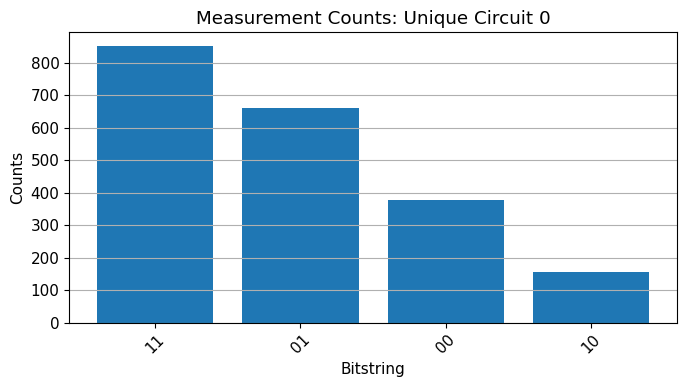

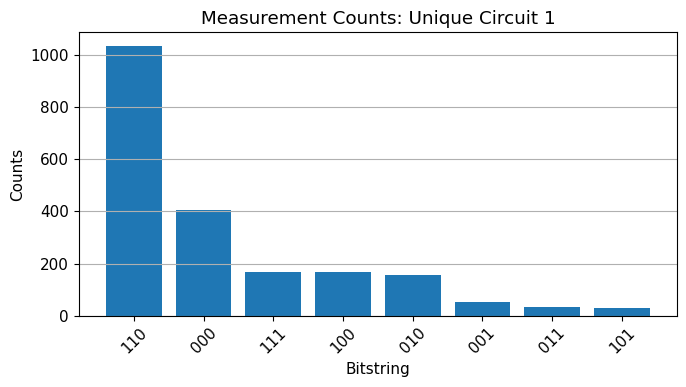

In [123]:
# 11.14 測定結果を視覚的に確認する

n_circuits = len(unique_counts_list)

for i, counts in enumerate(unique_counts_list):
    labels = list(counts.keys())
    values = list(counts.values())

    # 多すぎる場合は上位10件に絞る
    sorted_items = sorted(counts.items(), key=lambda x: x[1], reverse=True)[:10]
    labels = [k for k, _ in sorted_items]
    values = [v for _, v in sorted_items]

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(labels, values)
    ax.set_title(f"Measurement Counts: Unique Circuit {i}")
    ax.set_xlabel("Bitstring")
    ax.set_ylabel("Counts")
    ax.grid(True, axis="y")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## 12. 配送問題として比較してまとめる

ここでは、分割後の部分回路を実行して得られた結果を整理し、配送問題の観点から比較できる形にまとめます。

本来、回路分割では各部分回路の結果を厳密な再構成手順に従って結合し、元の回路に対応する量を推定します。  
本チュートリアルでは、まずは分割後に得られた測定結果を一覧化し、どの回路・どの役割・どの assignment に対応する結果なのかを見やすく整理します。

この整理により、QuantumCircuitCutting を用いて得られた実行結果を、元の配送問題の文脈へ戻して比較する準備が整います。

In [124]:
# 12.1 再構成に使う結果一覧を表で整理する

result_rows = []

for i, (my_circ, counts, subqc_res) in enumerate(zip(dedup_result.unique_circuits, unique_counts_list, subqc_results)):
    total_counts = sum(counts.values())
    top_bitstring, top_count = max(counts.items(), key=lambda x: x[1])

    result_rows.append({
        "unique_circuit_index": i,
        "subqc_id": getattr(my_circ, "subqc_id", None),
        "role": getattr(my_circ, "subcircuit_role", None),
        "assignment": str(getattr(subqc_res, "assignment", None)),
        "num_outcomes": len(counts),
        "top_bitstring": top_bitstring,
        "top_count": top_count,
        "top_ratio": top_count / total_counts if total_counts > 0 else None,
        "shots": total_counts,
    })

df_result_summary = pd.DataFrame(result_rows)
df_result_summary

,unique_circuit_index,subqc_id,role,assignment,num_outcomes,top_bitstring,top_count,top_ratio,shots
0,0,None,time0_left,"Assignment(space_assign=(), time_assign=((0, 1...",4,11,852,0.416016,2048
1,1,None,time0_right,"Assignment(space_assign=(), time_assign=((0, 1...",8,110,1035,0.505371,2048


### 12.2 前半の解と後半の部分回路結果を並べて確認する

ここでは、前半で `qudas` により得られた配送先割当結果と、後半で分割後の部分回路から得られた代表的なビット列を並べて確認します。

この時点では、後半の結果はまだ部分回路ごとの出力であり、全体の配送先割当へ完全には戻していません。  
しかし、前半の最終解と後半の部分結果を並べて見ることで、次に行う再構成と比較の準備ができます。

In [125]:
# 12.2 前半の解と後半の部分回路結果を並べて確認する

# 前半の最終解
front_assignment_str = "".join(str(x) for x in best_assignment)

# 後半の部分回路ごとの代表ビット列
partial_result_rows = []

for _, row in df_result_summary.iterrows():
    partial_result_rows.append({
        "source": "circuit cutting partial result",
        "role": row["role"],
        "bitstring": row["top_bitstring"],
        "top_ratio": row["top_ratio"],
    })

df_front_vs_partial = pd.DataFrame(
    [{"source": "qudas solution", "role": "full_assignment", "bitstring": front_assignment_str, "top_ratio": None}]
    + partial_result_rows
)

df_front_vs_partial

,source,role,bitstring,top_ratio
0,qudas solution,full_assignment,01100011,NaN
1,circuit cutting partial result,time0_left,11,0.416016
2,circuit cutting partial result,time0_right,110,0.505371


### 12.3 部分回路の結果から全体の代表ビット列を組み立てる

次に、後半で得られた部分回路ごとの代表ビット列を、元の量子ビット番号に対応づけながら全体の代表ビット列へ組み立てます。

ここでは簡単な再構成として、

- 各部分回路で最も多く観測されたビット列を使う
- 各部分回路の量子ビット対応表に従って、元の量子ビット位置へ戻す
- 複数の部分回路から同じ量子ビットへの候補が出た場合は、多数決で決める

という方法を用います。

この再構成は厳密な理論再構成そのものではありませんが、チュートリアルとして、分割後の結果を元の配送先割当へ戻して比較する流れを確認するのに適しています。

In [126]:
# 12.3 部分回路の結果から全体の代表ビット列を組み立てる

from collections import defaultdict, Counter

# 部分回路の代表ビット列
partial_top_bitstrings = {
    "time0_left": df_result_summary.loc[df_result_summary["role"] == "time0_left", "top_bitstring"].iloc[0],
    "time0_right": df_result_summary.loc[df_result_summary["role"] == "time0_right", "top_bitstring"].iloc[0],
}

# 量子ビット対応表
partial_qubit_maps = {
    "time0_left": sub_qc_1_qubit_map,
    "time0_right": sub_qc_2_qubit_map,
}

# 各元量子ビットに対する候補ビットを集約
votes_by_original_qubit = defaultdict(list)

for role, bitstring in partial_top_bitstrings.items():
    qubit_map = partial_qubit_maps[role]

    # Qiskit の bitstring は右端が qubit 0 側になりやすいため反転して扱う
    bitstring_reversed = bitstring[::-1]

    for local_idx, bit_char in enumerate(bitstring_reversed):
        if local_idx in qubit_map:
            original_idx = qubit_map[local_idx]
            votes_by_original_qubit[original_idx].append(int(bit_char))

# 多数決で全体割当を作る
reconstructed_assignment = np.zeros(n_small, dtype=int)

for original_idx in range(n_small):
    votes = votes_by_original_qubit.get(original_idx, [0])
    reconstructed_assignment[original_idx] = Counter(votes).most_common(1)[0][0]

reconstructed_assignment_str = "".join(str(x) for x in reconstructed_assignment)

print("Partial top bitstrings:")
print(partial_top_bitstrings)

print("\nVotes by original qubit:")
print(dict(votes_by_original_qubit))

print("\nReconstructed assignment:")
print(reconstructed_assignment)
print("As bitstring:", reconstructed_assignment_str)

Partial top bitstrings:
{'time0_left': '11', 'time0_right': '110'}

Votes by original qubit:
{<Qubit register=(4, "q"), index=0>: [1], <Qubit register=(4, "q"), index=1>: [0], <Qubit register=(4, "q"), index=2>: [1], <Qubit register=(4, "q"), index=3>: [1]}

Reconstructed assignment:
[0 0 0 0]
As bitstring: 0000


### 12.4 前半と後半で得られたチーム分けを比較する

ここでは、小規模問題について、前半の最適化結果と、後半の回路分割結果から再構成した割当を並べて比較します。

前半では、QUBO を `qudas` とソルバーで解くことで配送先割当を得ました。  
後半では、同じ小規模問題に対応する量子回路を分割し、部分回路の実行結果から全体の割当を再構成しました。

この2つを配送先ごとに並べることで、最終的に「配送先がどのように 2 チームへ分けられたか」を比較できます。

In [127]:
# 12.4 前半と後半で得られたチーム分けを比較する

# 小規模問題を前半と同じ流れで解く
qudata_small = QuData.input().from_array(qubo_matrix_small)
result_neal_small = solve_with_neal(qudata_small, num_reads=200)
best_assignment_small = assignment_dict_to_array(result_neal_small["assignment"])

# 比較表を作成
df_small_compare = df_points_small.copy()
df_small_compare["assignment_qudas"] = best_assignment_small
df_small_compare["team_qudas"] = df_small_compare["assignment_qudas"].map({0: "Team A", 1: "Team B"})

df_small_compare["assignment_cutting"] = reconstructed_assignment
df_small_compare["team_cutting"] = df_small_compare["assignment_cutting"].map({0: "Team A", 1: "Team B"})

df_small_compare["match"] = df_small_compare["assignment_qudas"] == df_small_compare["assignment_cutting"]

df_small_compare[[
    "destination",
    "x",
    "y",
    "assignment_qudas",
    "team_qudas",
    "assignment_cutting",
    "team_cutting",
    "match",
]]

,destination,x,y,assignment_qudas,team_qudas,assignment_cutting,team_cutting,match
0,S0,7.580877,3.545260,0,Team A,0,Team A,True
1,S1,9.706980,8.931211,1,Team B,0,Team A,False
2,S2,7.783835,1.946387,1,Team B,0,Team A,False
3,S3,4.667210,0.438038,0,Team A,0,Team A,True


### 12.5 前半と後半のチーム分けを視覚的に比較する

ここでは、小規模問題について、前半の `qudas` による割当結果と、後半の回路分割結果から得た簡易再構成の割当結果を散布図で比較します。

これにより、各配送先がどのチームに割り当てられたかを視覚的に確認できます。  
前半と後半で一致している配送先と、一致していない配送先がある場合は、その違いも見やすくなります。

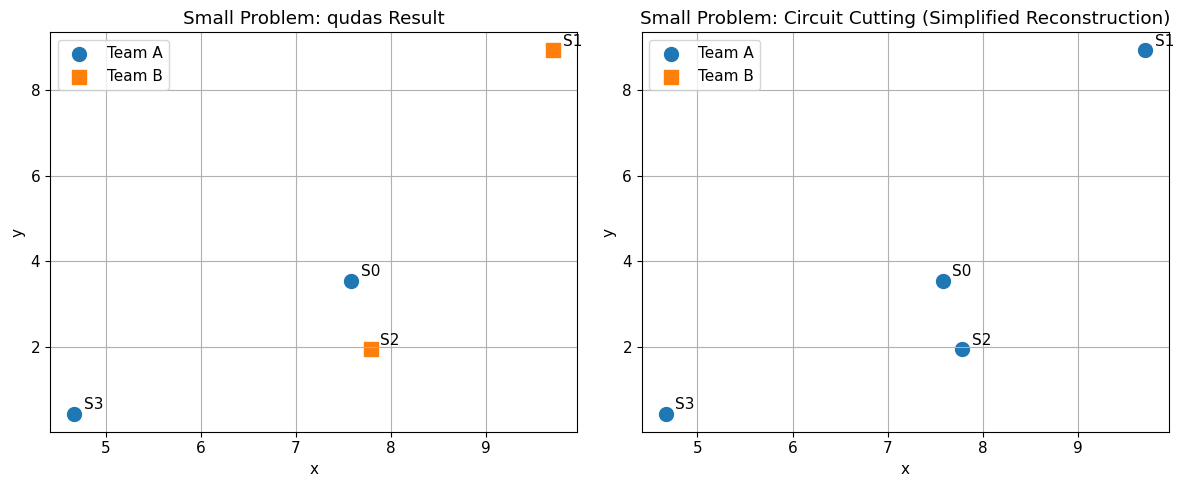

In [128]:
# 12.5 前半と後半のチーム分けを視覚的に比較する

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 前半: qudas
ax = axes[0]
for team_name, marker in [("Team A", "o"), ("Team B", "s")]:
    subset = df_small_compare[df_small_compare["team_qudas"] == team_name]
    ax.scatter(subset["x"], subset["y"], s=100, marker=marker, label=team_name)

for _, row in df_small_compare.iterrows():
    ax.text(row["x"] + 0.1, row["y"] + 0.1, row["destination"])

ax.set_title("Small Problem: qudas Result")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True)
ax.legend()

# 後半: circuit cutting
ax = axes[1]
for team_name, marker in [("Team A", "o"), ("Team B", "s")]:
    subset = df_small_compare[df_small_compare["team_cutting"] == team_name]
    ax.scatter(subset["x"], subset["y"], s=100, marker=marker, label=team_name)

for _, row in df_small_compare.iterrows():
    ax.text(row["x"] + 0.1, row["y"] + 0.1, row["destination"])

ax.set_title("Small Problem: Circuit Cutting (Simplified Reconstruction)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()

### 12.6 簡易再構成結果としての解釈

ここで得られた後半の割当結果は、分割後の部分回路の測定結果から、最頻ビット列と多数決を用いて簡易的に再構成したものです。  
そのため、前半の `qudas` による最適化結果と完全に一致することを保証するものではありません。

本チュートリアルでは、厳密な理論再構成そのものを実装することよりも、

- 配送問題に対応する量子回路を作成する
- QuantumCircuitCutting 系ライブラリで分割する
- 部分回路を生成する
- 部分回路を実行する
- その結果を簡易的に元の問題へ戻して比較する

という一連の流れを体験することを重視しています。

したがって、後半の結果は「厳密解」ではなく、**回路分割と部分回路実行の流れを確認するための簡易再構成結果**として解釈します。

## 13. まとめ

このチュートリアルでは、物流配送先割当問題を題材として、最適化問題の作成から回路分割後の部分回路実行までを一連の流れで確認しました。

前半では、配送先割当問題を 0/1 の最適化問題として表し、QUBO 行列を作成して `qudas` により解きました。  
これにより、配送先を 2 つのチームへ割り当てる基本的な流れを確認しました。

後半では、小規模な配送問題に対応する量子回路を作成し、QuantumCircuitCutting 系ライブラリを用いて

- カット位置の探索
- ワイヤカットを含む回路の生成
- 部分回路の作成
- 実行可能回路群への展開
- 部分回路の実行
- 簡易再構成による比較

までを行いました。

このように、本チュートリアルでは、1 つの配送問題を

- 組合せ最適化問題
- 小規模量子回路
- 回路分割された部分回路群

という複数の見方で扱い、それぞれの処理のつながりを確認しました。

本チュートリアルの目的は、配送問題に対する厳密な量子回路分割再構成を完成させることではなく、**配送問題を題材として、量子回路分割の実装フローを一通り体験すること**にあります。

### 13.1 今後の発展課題

今後の発展としては、たとえば次のような方向が考えられます。

- 部分回路結果の厳密な再構成手順を実装する
- より大きな配送問題に対して分割戦略を比較する
- ゲートカットとワイヤカットの違いを比較する
- 分割前後の実行コストや必要ショット数を評価する
- `circuit_cutter` を含む QuantumCircuitCutting 系ライブラリをさらに広く活用する

これらを進めることで、チュートリアル段階から、より実践的な量子回路分割と量子最適化の検討へつなげることができます。